# 01 · PCA and SOM training (Figure 5, SM3-SM6)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development (under review).

**What this notebook does**
1. **PCA** of the seven z-score standardized major ions of the 406 complete samples (Kohonen, 2013; Bastianoni et al., 2021): eigenvalues, correlation circles and score plot. The ratio √(λ₁/λ₂) sets the aspect ratio of the SOM grid.
2. **SOM grid search**: candidate hexagonal grids of 30-132 neurons around the Vesanto target 5√N, compared by the TE/QE ratio.
3. **Grid comparison**: eight grids of 42-99 neurons compared by TE/QE, proportion of empty neurons and maximum samples per neuron; the **8 × 9 grid (72 neurons)** is selected.
4. **Final SOM** (8 × 9, hexagonal, PCA initialization, batch training, 10,000 iterations), its diagnostics, and the saved model for clustering.

| | |
|---|---|
| **Input** | `outputs/intermediate/data_preprocessed_full.xlsx` (from `01_data_preparation/02_preprocessing.ipynb`) |
| **Figures** | `Figure5_PCA_combined_scree_corrcircle`, `SM03_PCA_correlation_circle_PC3_PC4`, `SM04_PCA_scores_PC1_PC2`, `SM05_SOM_grid_optimization_TE_QE`, `SM06_SOM_grid_selection_multicriteria`; SOM diagnostics `Diag_*` (not in the article) |
| **Tables** | `outputs/tables/som_grid_optimization_metrics.xlsx` |
| **Outputs** | `outputs/intermediate/som_model_final.p`, `som_codebook_vectors.npy`, `som_bmu_assignments.xlsx` |
| **Next notebook** | `02_HCA_clustering.ipynb` |

*Runtime: the grid search trains 18 grids × 10 runs and takes several minutes.*

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Core ──────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import sklearn
import minisom
import pickle, warnings
from pathlib import Path

# ── SOM ───────────────────────────────────────────────────────────────
from minisom import MiniSom

# ── PCA ───────────────────────────────────────────────────────────────
from sklearn.decomposition import PCA

# ── Plotting helpers ──────────────────────────────────────────────────
from matplotlib.gridspec import GridSpec
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ── Settings ─────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
    "savefig.transparent": False,
})

SEED = 42
np.random.seed(SEED)

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_TABLES   = ROOT / "outputs" / "tables"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_TABLES, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)

print("Package versions:")
for name, mod in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib),
                  ("scikit-learn", sklearn), ("minisom", minisom)]:
    print(f"  {name:14s} {getattr(mod, '__version__', 'installed')}")
print(f"\nRandom seed: {SEED}")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Package versions:
  numpy          1.26.4
  pandas         2.2.3
  matplotlib     3.7.2
  scikit-learn   1.9.0
  minisom        installed

Random seed: 42


### <font color='orange'> **2) Load the preprocessed data** </font>

Output of `02_preprocessing.ipynb`: metadata + mg/L + meq/L + relative % + z-scores. PCA and the SOM use the **z-score columns** only.

In [2]:
# ── Load the output of 02_preprocessing.ipynb ───────────────────────
DATA_FILE = DIR_INTERMED / "data_preprocessed_full.xlsx"
print(f"Input file : {DATA_FILE.relative_to(ROOT)}  (exists: {DATA_FILE.is_file()})")

df = pd.read_excel(DATA_FILE)

# ── Column groups (as in 02_preprocessing.ipynb) ─────────────────────
MAJOR_IONS  = ["Ca (mg/L)", "Mg (mg/L)", "Na (mg/L)", "K (mg/L)",
               "HCO3 (mg/L)", "Cl (mg/L)", "SO4 (mg/L)"]
IONS_MEQ    = [c.replace("(mg/L)", "(meq/L)") for c in MAJOR_IONS]
IONS_REL    = [c.replace("(mg/L)", "(%)") for c in MAJOR_IONS]
IONS_SCALED = [c.replace("(mg/L)", "(scaled)") for c in MAJOR_IONS]
ION_LABELS  = [c.replace(" (mg/L)", "") for c in MAJOR_IONS]
META_COLS   = [c for c in df.columns if c not in MAJOR_IONS + IONS_MEQ + IONS_REL + IONS_SCALED + ["Total_meq"]]

# ── SOM input matrix (standardized relative concentrations) ─────────
data_som = df[IONS_SCALED].values  # numpy array for MiniSom

print(f"\nDataset shape  : {df.shape[0]} samples × {df.shape[1]} columns")
print(f"SOM input shape: {data_som.shape} (samples × features)")
print(f"Features       : {ION_LABELS}")
print(f"Metadata       : {META_COLS}")

print(f"\n── Sample types ───────────────────────────────────────────")
print(df["Type"].value_counts().to_string())

Input file : outputs\intermediate\data_preprocessed_full.xlsx  (exists: True)

Dataset shape  : 406 samples × 35 columns
SOM input shape: (406, 7) (samples × features)
Features       : ['Ca', 'Mg', 'Na', 'K', 'HCO3', 'Cl', 'SO4']
Metadata       : ['Reference', 'SampleID', 'Type', 'Sampling date', 'X', 'Y']

── Sample types ───────────────────────────────────────────
Type
Groundwater    305
Spring          49
Stream          40
Snow             3
Dam              2
Rain             2
Irrigation       2
Tributary        2
Lac              1


### <font color='orange'> **3) Principal Component Analysis (PCA)** </font>

> PCA serves two purposes in this workflow:
> 
> **Purpose 1 - SOM grid design:**  
> The ratio of the two largest eigenvalues (λ₁/λ₂) determines the aspect ratio of the SOM grid.  
> *"The ratio of the axes of the lattice should correspond to the ratio of the standard deviations in the data given by the two largest principal components."* - Kohonen (2013)
> 
> **Purpose 2 - Hydrochemical interpretation:**  
> Loading vectors reveal which ions drive the variance, helping interpret the geochemical processes controlling groundwater chemistry.
> 
> ---
> 
> #### Strategy
> 
> **Data:** PCA is applied on the **standardized relative concentrations** (z-score of meq/L %) - the same matrix used as SOM input. This ensures consistency between PCA interpretation and SOM behavior.
> 
> **Retain:** all PCs with **eigenvalue ≥ 1** (Kaiser criterion); PC3 and PC4 are also shown (Figure SM3) to describe secondary processes.
> 
> #### Outputs
> 
> | Output | Description |
> |--------|-------------|
> | **Eigenvalue table** | All 7 PCs: eigenvalue, % variance, cumulative % |
> | **Figure 5** | (a) scree plot, (b) correlation circle PC1 vs PC2 |
> | **Figure SM3** | Correlation circle PC3 vs PC4 (secondary processes) |
> | **Figure SM4** | Score plot PC1 vs PC2, samples colored by water type |
> | **Grid aspect ratio** | √(λ₁/λ₂) → used in section 4 for the SOM grid design |
> 
> *References: Bastianoni et al. (2021) §2.2.2 & §3.2; Astel et al. (2007); Kohonen (2013)*

#### **3.1 Eigenvalue table**

> Kaiser criterion: retain PCs with eigenvalue ≥ 1. The λ₁/λ₂ ratio gives the SOM grid aspect ratio.  
> PC signs are fixed explicitly (Cl⁻ positive on PC1, K⁺ on PC2, SO₄²⁻ on PC3 and PC4), so the figures do not depend on the scikit-learn version.

In [3]:
# ── 3.1  PCA - Eigenvalue table ──────────────────────────────────────

# Run PCA on the standardized relative concentrations (SOM input matrix)
# n_components = None → compute all 7 PCs
pca = PCA(n_components=None, random_state=SEED)
pca.fit(data_som)

# ── Fixed sign convention ────────────────────────────────────────────
# The sign of a principal component is arbitrary and differs between scikit-learn
# versions. The axes are oriented as in the article: Cl- positive on PC1, K+ on PC2,
# SO4 2- on PC3 and PC4 (the scores from pca.transform follow the same signs).
SIGN_REF = {0: "Cl", 1: "K", 2: "SO4", 3: "SO4"}
for k, ion in SIGN_REF.items():
    if pca.components_[k, ION_LABELS.index(ion)] < 0:
        pca.components_[k] *= -1

# ── Eigenvalue table ─────────────────────────────────────────────────
n_pcs = len(pca.explained_variance_)
eigenvalues = pca.explained_variance_
var_pct = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(var_pct)

df_eigen = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(n_pcs)],
    "Eigenvalue": eigenvalues.round(4),
    "Variance (%)": var_pct.round(2),
    "Cumulative (%)": cum_var.round(2),
    "Kaiser (≥1)": ["✓" if ev >= 1.0 else "" for ev in eigenvalues],
})

print("── PCA Eigenvalue Table ───────────────────────────────────\n")
display(df_eigen)

# Number of PCs retained (Kaiser criterion: eigenvalue ≥ 1)
n_retained = (eigenvalues >= 1.0).sum()
print(f"\nRetained PCs (Kaiser criterion): {n_retained}")
print(f"Cumulative variance explained : {cum_var[n_retained-1]:.1f}%")

# ── SOM grid aspect ratio from PCA ───────────────────────────────────
# Kohonen (2013): grid ratio = sqrt(λ1 / λ2)
lambda1, lambda2 = eigenvalues[0], eigenvalues[1]
grid_ratio = np.sqrt(lambda1 / lambda2)

print(f"\n── SOM Grid Ratio ─────────────────────────────────────────")
print(f"λ1 = {lambda1:.4f}")
print(f"λ2 = {lambda2:.4f}")
print(f"Grid aspect ratio = √(λ1/λ2) = {grid_ratio:.3f}")

── PCA Eigenvalue Table ───────────────────────────────────



,PC,Eigenvalue,Variance (%),Cumulative (%),Kaiser (≥1)
0,PC1,2.5771,36.73,36.73,✓
1,PC2,1.8220,25.96,62.69,✓
2,PC3,1.2943,18.44,81.13,✓
3,PC4,0.7854,11.19,92.33,
4,PC5,0.3916,5.58,97.91,
5,PC6,0.1469,2.09,100.00,
6,PC7,0.0000,0.00,100.00,



Retained PCs (Kaiser criterion): 3
Cumulative variance explained : 81.1%

── SOM Grid Ratio ─────────────────────────────────────────
λ1 = 2.5771
λ2 = 1.8220
Grid aspect ratio = √(λ1/λ2) = 1.189


#### **3.2 Correlation loadings**

> Correlation between each ion and each PC (eigenvector × √eigenvalue). Ions pointing together are positively correlated (same geochemical process); ions pointing in opposite directions are negatively correlated.

In [4]:
# ── 3.2  PCA - Correlation loadings ──────────────────────────────────
# Proper correlation loadings = eigenvector × √(eigenvalue)
# This gives the correlation between each variable and each PC.
# Only with this scaling does the unit circle represent |correlation| = 1.

loadings_raw = pca.components_                        # eigenvectors (n_pcs, 7)
sqrt_eigenvalues = np.sqrt(pca.explained_variance_)   # √(λ)

# Correlation loadings: scale each eigenvector row by its √(eigenvalue)
corr_loadings = loadings_raw.T * sqrt_eigenvalues     # shape: (7, n_pcs)

# LaTeX-style labels for publication
tex_labels = {
    "Ca":   r"$\mathrm{Ca^{2+}}$",
    "Mg":   r"$\mathrm{Mg^{2+}}$",
    "Na":   r"$\mathrm{Na^{+}}$",
    "K":    r"$\mathrm{K^{+}}$",
    "HCO3": r"$\mathrm{HCO_{3}^{-}}$",
    "Cl":   r"$\mathrm{Cl^{-}}$",
    "SO4":  r"$\mathrm{SO_{4}^{2-}}$",
}


# ── Print correlation loading values ─────────────────────────────────
df_corr_loadings = pd.DataFrame(
    corr_loadings[:, :n_retained],
    columns=[f"PC{i+1}" for i in range(n_retained)],
    index=ION_LABELS,
)
print("── Correlation loadings (retained PCs) ─────────────────────\n")
display(df_corr_loadings.round(4))

── Correlation loadings (retained PCs) ─────────────────────



,PC1,PC2,PC3
Ca,-0.8663,-0.2598,-0.1948
Mg,0.0278,-0.5344,0.5505
Na,0.6360,-0.5255,-0.3440
K,0.2822,0.9500,0.1069
HCO3,-0.8814,-0.1846,-0.2988
Cl,0.7509,-0.4214,-0.3084
SO4,-0.0340,-0.2801,0.7995


#### **3.3 Figure 5: (a) scree plot and (b) correlation circle PC1 vs PC2**

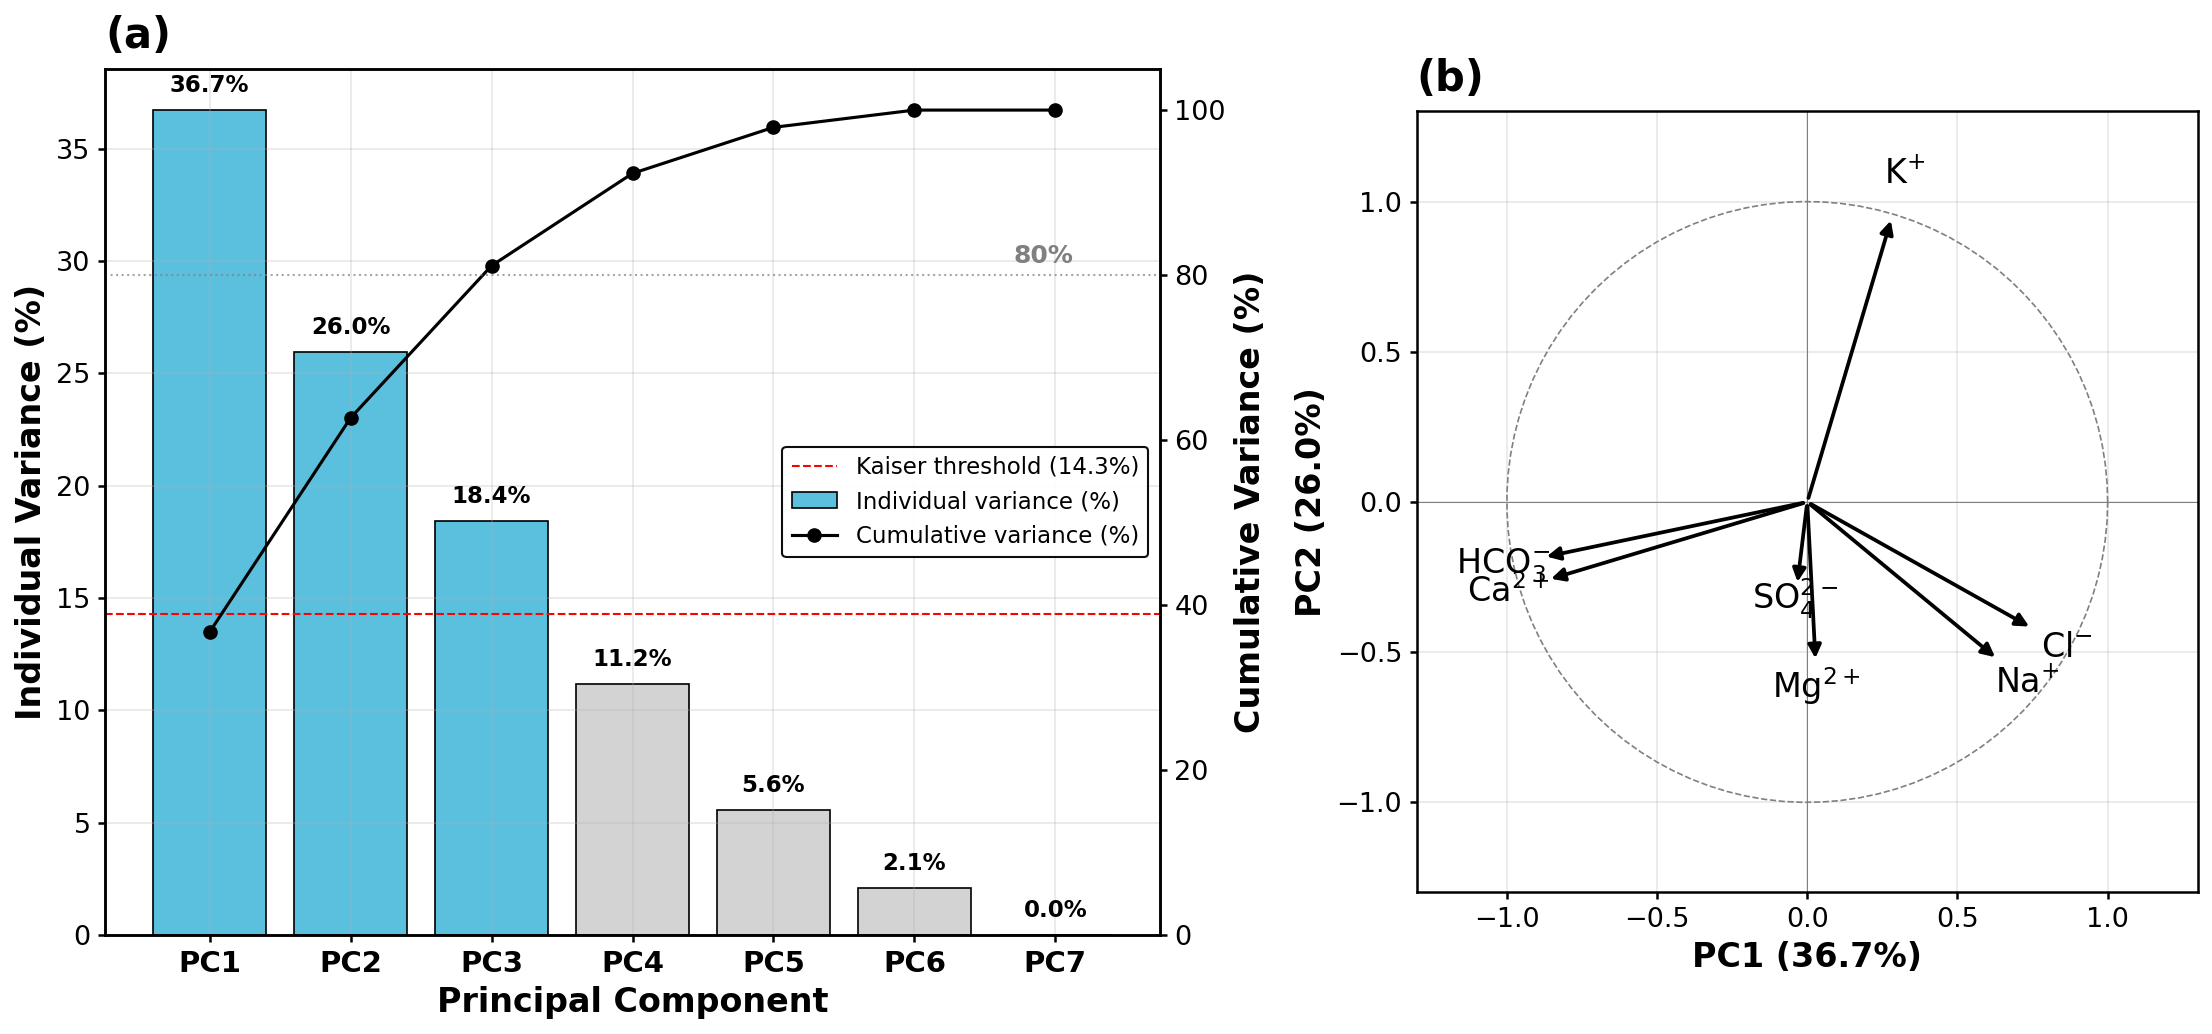

Saved: Figure5_PCA_combined_scree_corrcircle.png


In [5]:
# ── Figure 5: scree plot (a) + correlation circle PC1 vs PC2 (b) ─────

fig = plt.figure(figsize=(18, 7.5))
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.35, 1], wspace=0.28)

# ═══ Panel (a): Scree plot ═══════════════════════════════════════════
ax_a = fig.add_subplot(gs[0, 0])

bars = ax_a.bar(range(1, n_pcs+1), var_pct, color="lightgray",
                edgecolor="black", linewidth=0.8, label="Individual variance (%)")
for i in range(n_retained):
    bars[i].set_facecolor("#5BC0DE")

ax_a.set_xlabel("Principal Component", fontsize=16, fontweight="bold")
ax_a.set_ylabel("Individual Variance (%)", fontsize=16, fontweight="bold")
ax_a.set_xticks(range(1, n_pcs+1))
ax_a.set_xticklabels([f"PC{i+1}" for i in range(n_pcs)],
                     fontsize=14, fontweight="bold")
ax_a.tick_params(axis="y", labelsize=13)

kaiser_pct = 100 / n_pcs
ax_a.axhline(y=kaiser_pct, color="red", linestyle="--", linewidth=1,
             label=f"Kaiser threshold ({kaiser_pct:.1f}%)")

# Twin axis: cumulative variance
ax_a2 = ax_a.twinx()
ax_a2.plot(range(1, n_pcs+1), cum_var, "o-", color="black",
           linewidth=1.5, markersize=6, label="Cumulative variance (%)")
ax_a2.set_ylabel("Cumulative Variance (%)", fontsize=16, fontweight="bold")
ax_a2.set_ylim(0, 105)
ax_a2.tick_params(axis="y", labelsize=13)
ax_a2.axhline(y=80, color="gray", linestyle=":", linewidth=1, alpha=0.7)
ax_a2.text(n_pcs - 0.3, 81.5, "80%", fontsize=12, color="gray", fontweight="bold")
ax_a2.grid(False)  # avoid double-grid from twinx

for i, v in enumerate(var_pct):
    ax_a.text(i+1, v + 0.8, f"{v:.1f}%", ha="center",
              fontsize=11, fontweight="bold")

# Panel label (a) - top-left, outside axes area
ax_a.set_title("(a)", fontsize=20, fontweight="bold", loc="left", pad=10)

# Combined legend (placed inside panel)
lines1, labels1 = ax_a.get_legend_handles_labels()
lines2, labels2 = ax_a2.get_legend_handles_labels()
ax_a.legend(lines1 + lines2, labels1 + labels2, loc="center right",
            fontsize=11, framealpha=0.95, edgecolor="black")

for spine in ax_a.spines.values():
    spine.set_edgecolor("black"); spine.set_linewidth(1.2)
for spine in ax_a2.spines.values():
    spine.set_edgecolor("black"); spine.set_linewidth(1.2)
ax_a.tick_params(axis="both", colors="black", width=1.2)
ax_a2.tick_params(axis="both", colors="black", width=1.2)

# ═══ Panel (b): Correlation circle PC1 vs PC2 ═══════════════════════
ax_b = fig.add_subplot(gs[0, 1])

theta = np.linspace(0, 2 * np.pi, 100)
ax_b.plot(np.cos(theta), np.sin(theta),
          color="gray", linewidth=0.8, linestyle="--")

for j, ion in enumerate(ION_LABELS):
    x = corr_loadings[j, 0]
    y = corr_loadings[j, 1]
    ax_b.annotate(
        "", xy=(x, y), xytext=(0, 0),
        arrowprops=dict(arrowstyle="-|>", color="black", linewidth=1.8),
    )
    ax_b.text(x * 1.15, y * 1.15, tex_labels[ion],
              fontsize=16, ha="center", va="center", fontweight="bold")

ax_b.axhline(0, color="gray", linewidth=0.5, linestyle="-")
ax_b.axvline(0, color="gray", linewidth=0.5, linestyle="-")
ax_b.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)", fontsize=16, fontweight="bold")
ax_b.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)", fontsize=16, fontweight="bold")
ax_b.set_title("(b)", fontsize=20, fontweight="bold", loc="left", pad=10)
ax_b.set_xlim(-1.3, 1.3)
ax_b.set_ylim(-1.3, 1.3)
ax_b.set_aspect("equal")
ax_b.tick_params(axis="both", labelsize=13)
for spine in ax_b.spines.values():
    spine.set_edgecolor("black"); spine.set_linewidth(1.2)
ax_b.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "Figure5_PCA_combined_scree_corrcircle.png", dpi=300)
plt.show()

print("Saved: Figure5_PCA_combined_scree_corrcircle.png")

#### **3.4 Figure SM4: score plot (PC1 vs PC2), samples colored by water type**

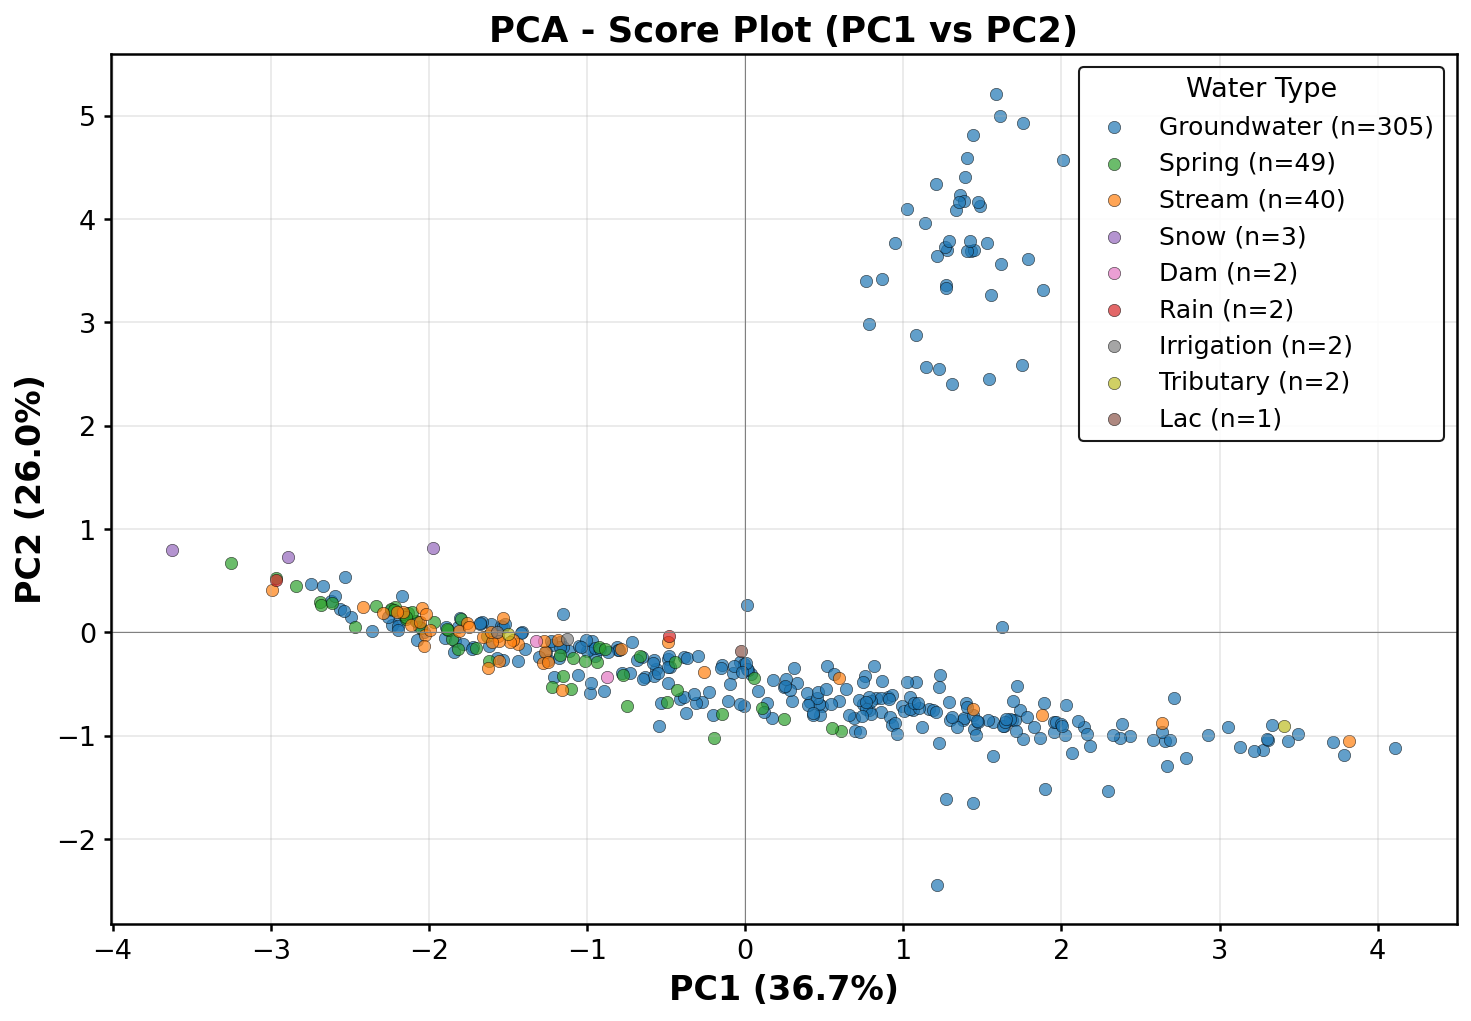

In [6]:
# ── 3.3  PCA - Score plot (PC1 vs PC2) colored by Type ───────────────

# Project samples onto PC space
scores = pca.transform(data_som)  # shape: (406, 7)

# Add scores to a temporary dataframe for plotting
df_scores = pd.DataFrame({
    "PC1": scores[:, 0],
    "PC2": scores[:, 1],
    "Type": df["Type"].values,
})

# Color palette - one color per water type, ordered by frequency
type_order = df["Type"].value_counts().index.tolist()
palette = {
    "Groundwater": "#1f77b4",   # blue
    "Spring":      "#2ca02c",   # green
    "Stream":      "#ff7f0e",   # orange
    "Snow":        "#9467bd",   # purple
    "Rain":        "#d62728",   # red
    "Lac":         "#8c564b",   # brown
    "Dam":         "#e377c2",   # pink
    "Irrigation":  "#7f7f7f",   # gray
    "Tributary":   "#bcbd22",   # olive
    "Zaraba":      "#17becf",   # cyan
}
# Keep only types present in the data
palette = {k: v for k, v in palette.items() if k in type_order}

fig, ax = plt.subplots(figsize=(10, 7))

for wtype in type_order:
    mask = df_scores["Type"] == wtype
    n = mask.sum()
    ax.scatter(
        df_scores.loc[mask, "PC1"],
        df_scores.loc[mask, "PC2"],
        c=palette.get(wtype, "gray"),
        label=f"{wtype} (n={n})",
        s=35, alpha=0.7, edgecolors="black", linewidths=0.3,
    )

ax.axhline(0, color="gray", linewidth=0.5, linestyle="-")
ax.axvline(0, color="gray", linewidth=0.5, linestyle="-")

ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)", fontsize=16, fontweight="bold")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)", fontsize=16, fontweight="bold")
ax.set_title("PCA - Score Plot (PC1 vs PC2)", fontsize=17, fontweight="bold")
ax.tick_params(axis="both", labelsize=13)

ax.legend(fontsize=12, loc="best", framealpha=0.9, edgecolor="black", title="Water Type", title_fontsize=13)

# Black axes
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)
ax.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM04_PCA_scores_PC1_PC2.png", dpi=300)
plt.show()

#### **3.5 Figure SM3: correlation circle PC3 vs PC4 (secondary processes)**

> PC3 and PC4 add about 30% of the variance and show secondary geochemical processes not captured by the first two components.

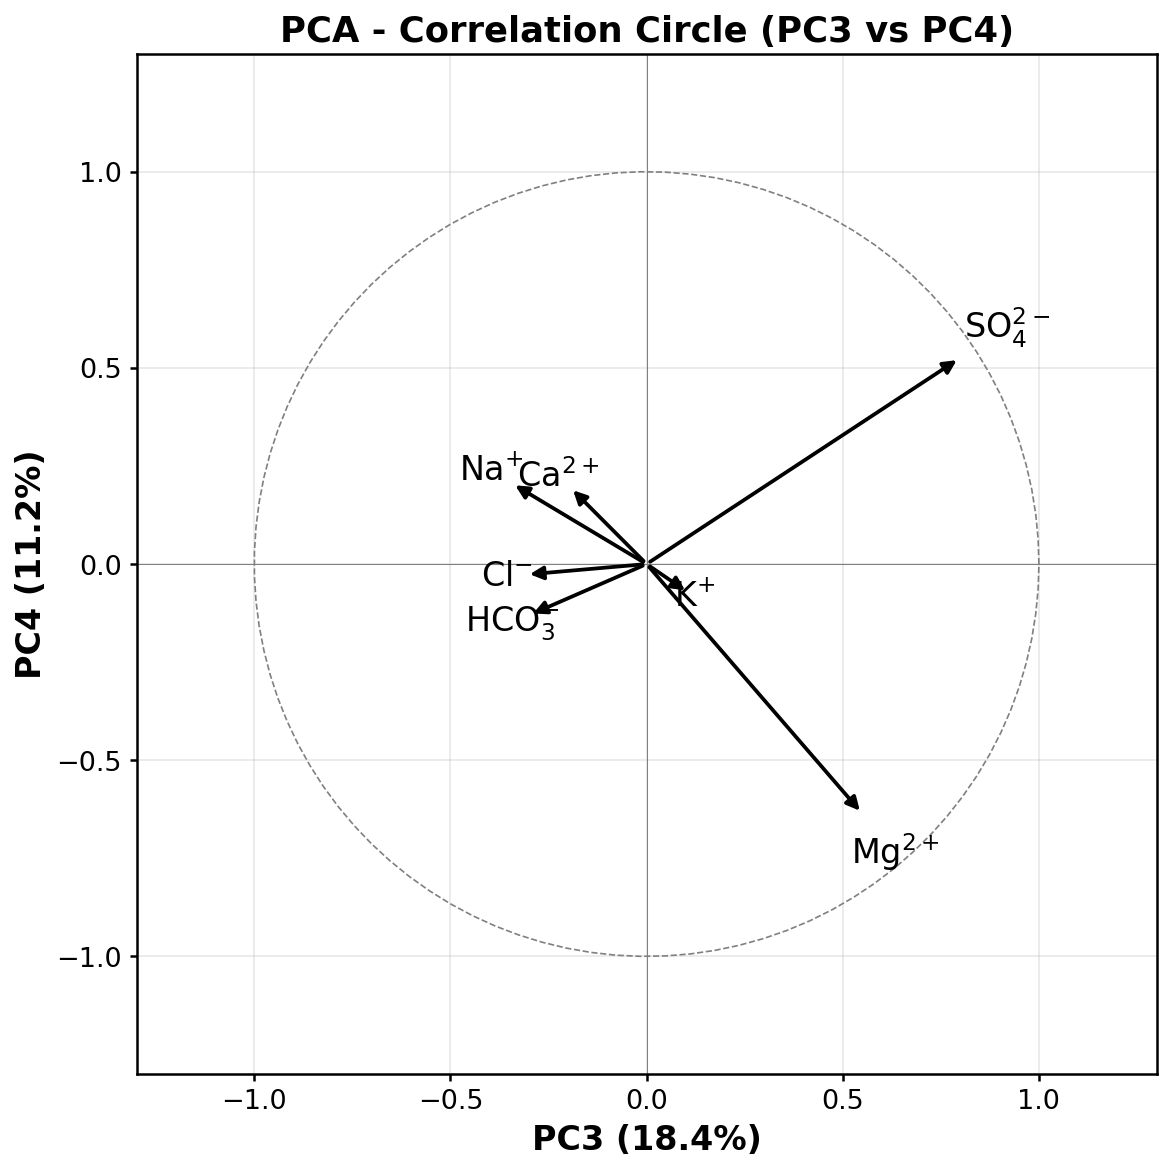

── Correlation loadings (PC3 & PC4) ────────────────────────



,Ion,PC3,PC4
0,Ca,-0.1948,0.1955
1,Mg,0.5505,-0.6369
2,Na,-0.3440,0.2060
3,K,0.1069,-0.0731
4,HCO3,-0.2988,-0.1302
5,Cl,-0.3084,-0.0269
6,SO4,0.7995,0.5255



Cumulative variance PC1–PC4: 92.3%


In [7]:
# ── Figure SM3: correlation circle (PC3 vs PC4) ──────────────────────

fig, ax = plt.subplots(figsize=(9, 8))

# Unit circle
theta = np.linspace(0, 2 * np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), color="gray", linewidth=0.8, linestyle="--")

# Correlation loadings already computed: corr_loadings shape (7, n_pcs)
for j, ion in enumerate(ION_LABELS):
    x = corr_loadings[j, 2]  # correlation with PC3
    y = corr_loadings[j, 3]  # correlation with PC4
    ax.annotate(
        "", xy=(x, y), xytext=(0, 0),
        arrowprops=dict(arrowstyle="-|>", color="black", linewidth=1.8),
    )
    offset_x = x * 1.15
    offset_y = y * 1.15
    ax.text(offset_x, offset_y, tex_labels[ion],
            fontsize=16, ha="center", va="center", fontweight="bold")

# Reference lines
ax.axhline(0, color="gray", linewidth=0.5, linestyle="-")
ax.axvline(0, color="gray", linewidth=0.5, linestyle="-")

ax.set_xlabel(f"PC3 ({var_pct[2]:.1f}%)", fontsize=16, fontweight="bold")
ax.set_ylabel(f"PC4 ({var_pct[3]:.1f}%)", fontsize=16, fontweight="bold")
ax.set_title("PCA - Correlation Circle (PC3 vs PC4)", fontsize=17, fontweight="bold")
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.tick_params(axis="both", labelsize=13)

# Black axes
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)
ax.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM03_PCA_correlation_circle_PC3_PC4.png", dpi=300)
plt.show()

# ── Print PC3-PC4 correlation loadings ───────────────────────────────
print("── Correlation loadings (PC3 & PC4) ────────────────────────\n")
df_pc34 = pd.DataFrame({
    "Ion": ION_LABELS,
    "PC3": corr_loadings[:, 2].round(4),
    "PC4": corr_loadings[:, 3].round(4),
})
display(df_pc34)

print(f"\nCumulative variance PC1–PC4: {cum_var[3]:.1f}%")

### <font color='orange'> **4) SOM grid optimization** </font>

> Determine the SOM grid size before the final training.
> 
> The grid size (rows × columns) is critical: too small loses detail, too large creates empty neurons and overfits noise. Following Bastianoni et al. (2021) and Haselbeck et al. (2019), three criteria are combined:
> 
> ---
> 
> #### Criterion 1 - Approximate number of neurons (Vesanto rule)
> The optimal number of neurons is close to **M ≈ 5√N** (Vesanto et al., 1999).  
> With N = 406 samples: M ≈ 5 × √406 ≈ **101 neurons**.  
> This is the **target** around which we search - we test grids both below and above this value, and let the TE/QE ratio decide the actual optimum.
> 
> #### Criterion 2 - Grid aspect ratio (from PCA)
> The ratio of the grid axes should match the ratio of the standard deviations of the two largest principal components (Kohonen, 2013).  
> 
> Standard deviation of PCi = √λi, so:  
> **Grid ratio = √λ₁ / √λ₂ = √(λ₁/λ₂)**
> 
> This means if PC1 explains more variance than PC2, the grid should be slightly rectangular (more columns than rows). All candidate grids respect this ratio.
> 
> #### Criterion 3 - Minimum TE/QE ratio
> For each candidate grid, train a SOM and compute:
> - **QE (Quantization Error):** mean Euclidean distance between each sample and its BMU → measures representation accuracy
> - **TE (Topographic Error):** fraction of samples where the 1st and 2nd BMU are not adjacent → measures topology preservation
> - **TE/QE ratio:** balances both errors. Select the grid with **minimum TE/QE ratio**.
> 
> (Haselbeck et al., 2019; Bastianoni et al., 2021)
> 
> ---
> 
> #### Procedure
> 1. Compute target neurons (5√N ≈ 101) and grid ratio (√(λ₁/λ₂)) from PCA
> 2. Generate ~12 candidate grids around this target, all respecting the PCA aspect ratio
> 3. Train a SOM for each candidate (batch, PCA initialization, hexagonal, 5000 iterations)
> 4. Compute QE, TE, and TE/QE for each
> 5. Plot TE/QE vs. number of neurons (Figure SM5); the final choice also uses empty neurons and sample distribution (section 4.4, Figure SM6)
> 
> **Parameters held constant during grid search:** hexagonal topology, PCA initialization, Gaussian neighborhood, batch training, learning rate = 0.5, seed = 42.

#### 4.1 Target number of neurons and candidate grids

In [8]:
# ── 4.1  Target neurons & candidate grids (respecting the PCA aspect ratio) ─

N = len(data_som)

# ── Vesanto rule ─────────────────────────────────────────────────────
M_target = int(5 * np.sqrt(N))
print(f"Number of samples (N)     : {N}")
print(f"Vesanto target (5√N)      : {M_target} neurons")

# ── PCA grid aspect ratio ────────────────────────────────────────────
ratio = np.sqrt(lambda1 / lambda2)
print(f"\nPCA eigenvalues: λ1 = {lambda1:.4f}, λ2 = {lambda2:.4f}")
print(f"Grid aspect ratio √(λ1/λ2) = {ratio:.3f}")

# ── Generate candidates: systematic scan ─────────────────────────────
# For each row count (5 to 15), compute cols = round(rows * ratio)
# Then also test cols ± 1 to get finer spacing (~every 2 neurons)
candidates = []
for rows in range(5, 16):
    for cols_offset in [-1, 0, 1]:
        cols = round(rows * ratio) + cols_offset
        if cols < rows:
            continue  # keep cols >= rows (ratio >= 1)
        total = rows * cols
        if 30 <= total <= 140:
            candidates.append((rows, cols, total))

# Remove exact duplicates and sort by total neurons
candidates = list(set(candidates))
candidates = sorted(candidates, key=lambda x: x[2])

# Display candidates
print(f"\n── Candidate grids ({len(candidates)} configurations) ────────────────")
print(f"{'#':>3s}  {'Grid':>10s}  {'Neurons':>8s}  {'Ratio (c/r)':>12s}")
print("─" * 40)
for i, (r, c, t) in enumerate(candidates, 1):
    marker = " ◄" if t == min(candidates, key=lambda x: abs(x[2] - M_target))[2] else ""
    print(f"{i:3d}   {r:2d} × {c:2d}     {t:4d}        {c/r:.2f}{marker}")

print(f"\nTarget ≈ {M_target} neurons, ratio ≈ {ratio:.2f}")

Number of samples (N)     : 406
Vesanto target (5√N)      : 100 neurons

PCA eigenvalues: λ1 = 2.5771, λ2 = 1.8220
Grid aspect ratio √(λ1/λ2) = 1.189

── Candidate grids (18 configurations) ────────────────
  #        Grid   Neurons   Ratio (c/r)
────────────────────────────────────────
  1    5 ×  6       30        1.20
  2    5 ×  7       35        1.40
  3    6 ×  6       36        1.00
  4    6 ×  7       42        1.17
  5    6 ×  8       48        1.33
  6    7 ×  7       49        1.00
  7    7 ×  8       56        1.14
  8    7 ×  9       63        1.29
  9    8 ×  9       72        1.12
 10    8 × 10       80        1.25
 11    8 × 11       88        1.38
 12    9 × 10       90        1.11
 13    9 × 11       99        1.22 ◄
 14    9 × 12      108        1.33
 15   10 × 11      110        1.10
 16   10 × 12      120        1.20
 17   10 × 13      130        1.30
 18   11 × 12      132        1.09

Target ≈ 100 neurons, ratio ≈ 1.19


#### 4.2 Grid search: QE, TE and TE/QE for each candidate

> PCA initialization and batch training are deterministic, so the 10 runs per grid give identical values (standard deviation 0); the averaging is kept as in the original analysis.

In [9]:
# ── 4.2  Grid search: train SOM per candidate, compute QE/TE ────────
# Multiple runs per grid to get stable, reproducible results.
# This cell may take several minutes.

N_ITER_SEARCH = 5000   # iterations per run (enough for convergence)
N_RUNS = 10            # runs per grid (average smooths out stochasticity)
LR = 0.5

results = []

print(f"Training {len(candidates)} grids × {N_RUNS} runs × {N_ITER_SEARCH} iterations...\n")
print(f"{'Grid':>10s}  {'Neurons':>8s}  {'QE (avg)':>10s}  {'TE (avg)':>10s}  {'TE/QE (avg)':>12s}")
print("─" * 58)

for rows, cols, total in candidates:
    sigma = max(rows, cols) / 2
    qe_runs, te_runs = [], []

    for run in range(N_RUNS):
        som = MiniSom(
            rows, cols,
            data_som.shape[1],
            sigma=sigma,
            learning_rate=LR,
            neighborhood_function="gaussian",
            topology="hexagonal",
            random_seed=SEED + run,   # different seed per run
        )
        som.pca_weights_init(data_som)
        som.train_batch(data_som, N_ITER_SEARCH)

        qe_runs.append(som.quantization_error(data_som))
        te_runs.append(som.topographic_error(data_som))

    # Average across runs
    qe_avg = np.mean(qe_runs)
    te_avg = np.mean(te_runs)
    te_qe_avg = te_avg / qe_avg if qe_avg > 0 else np.inf

    results.append({
        "Rows": rows,
        "Cols": cols,
        "Neurons": total,
        "QE": round(qe_avg, 4),
        "TE": round(te_avg, 4),
        "TE/QE": round(te_qe_avg, 4),
        "QE_std": round(np.std(qe_runs), 4),
        "TE_std": round(np.std(te_runs), 4),
    })

    print(f"  {rows:2d} × {cols:2d}     {total:4d}      {qe_avg:.4f}    {te_avg:.4f}      {te_qe_avg:.4f}")

# Store results
df_grid = pd.DataFrame(results)

print(f"\n── Grid search complete ({N_RUNS} runs averaged) ────────────────")
display(df_grid)

# Save
grid_path = DIR_TABLES / "som_grid_optimization_metrics.xlsx"
df_grid.to_excel(grid_path, index=False)
print(f"\nSaved: {grid_path.relative_to(ROOT)}")

Training 18 grids × 10 runs × 5000 iterations...

      Grid   Neurons    QE (avg)    TE (avg)   TE/QE (avg)
──────────────────────────────────────────────────────────
   5 ×  6       30      1.1500    0.0419      0.0364
   5 ×  7       35      1.3847    0.0936      0.0676
   6 ×  6       36      1.0650    0.0222      0.0208
   6 ×  7       42      1.1635    0.0345      0.0296
   6 ×  8       48      1.1731    0.1059      0.0903
   7 ×  7       49      0.9929    0.0493      0.0496
   7 ×  8       56      1.0700    0.0246      0.0230
   7 ×  9       63      1.0977    0.0271      0.0247
   8 ×  9       72      1.0674    0.0271      0.0254
   8 × 10       80      1.0811    0.0542      0.0501
   8 × 11       88      1.0883    0.0197      0.0181
   9 × 10       90      1.0194    0.0099      0.0097
   9 × 11       99      1.0241    0.0493      0.0481
   9 × 12      108      1.0072    0.0419      0.0416
  10 × 11      110      0.9461    0.0197      0.0208
  10 × 12      120      0.9808    0.0

,Rows,Cols,Neurons,QE,TE,TE/QE,QE_std,TE_std
0,5,6,30,1.1500,0.0419,0.0364,0.0,0.0
1,5,7,35,1.3847,0.0936,0.0676,0.0,0.0
2,6,6,36,1.0650,0.0222,0.0208,0.0,0.0
3,6,7,42,1.1635,0.0345,0.0296,0.0,0.0
4,6,8,48,1.1731,0.1059,0.0903,0.0,0.0
5,7,7,49,0.9929,0.0493,0.0496,0.0,0.0
6,7,8,56,1.0700,0.0246,0.0230,0.0,0.0
7,7,9,63,1.0977,0.0271,0.0247,0.0,0.0
8,8,9,72,1.0674,0.0271,0.0254,0.0,0.0
9,8,10,80,1.0811,0.0542,0.0501,0.0,0.0



Saved: outputs\tables\som_grid_optimization_metrics.xlsx


#### 4.3 Figure SM5: TE/QE ratio vs. number of neurons

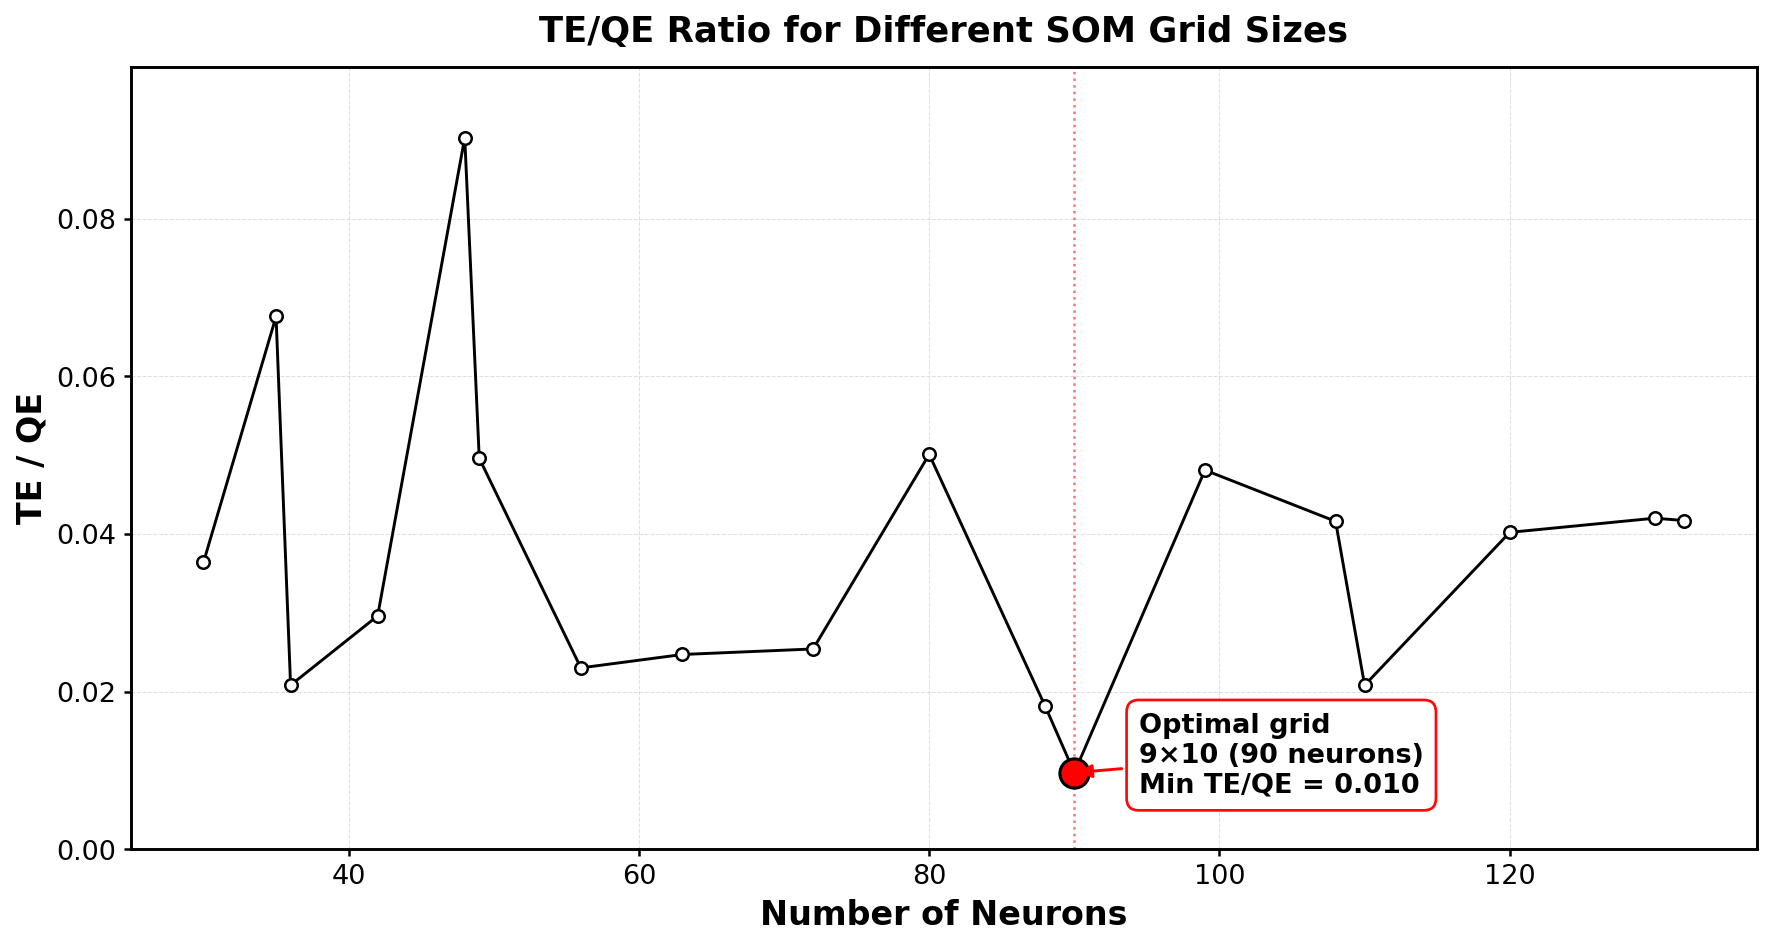


── Minimum TE/QE ──────────────────────────────────────────
  Grid size    : 9 × 10 = 90 neurons
  QE           : 1.0194
  TE           : 0.0099
  TE/QE        : 0.0097
  Vesanto (5√N): 100
  PCA ratio    : 1.189


In [10]:
# ── Figure SM5: TE/QE ratio vs. number of neurons ────────────────────

# Find the optimal grid (minimum TE/QE)
idx_best = df_grid["TE/QE"].idxmin()
best = df_grid.loc[idx_best]

fig, ax = plt.subplots(figsize=(12, 6.5))

# ── Main curve ───────────────────────────────────────────────────────
ax.plot(df_grid["Neurons"], df_grid["TE/QE"], "o-", color="black",
        linewidth=1.4, markersize=6, markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=1.2, zorder=3)

# ── Highlight optimal (minimum TE/QE) ────────────────────────────────
ax.plot(best["Neurons"], best["TE/QE"], "o", color="red",
        markersize=14, zorder=5,
        markeredgecolor="black", markeredgewidth=1.5)

# ── Faint vertical reference line at optimal ─────────────────────────
ax.axvline(x=best["Neurons"], color="red",
           linestyle=":", linewidth=1.2, alpha=0.55, zorder=1)

# ── Annotation BELOW the curve, simple straight arrow ────────────────
annotation_text = (
    f"Optimal grid\n"
    f"{int(best['Rows'])}×{int(best['Cols'])} "
    f"({int(best['Neurons'])} neurons)\n"
    f"Min TE/QE = {best['TE/QE']:.3f}"
)
ax.annotate(
    annotation_text,
    xy=(best["Neurons"], best["TE/QE"]),
    xytext=(0.62, 0.12), textcoords="axes fraction",
    fontsize=13, fontweight="bold", ha="left", va="center",
    arrowprops=dict(arrowstyle="-|>", color="red", linewidth=1.4),
    bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
              edgecolor="red", linewidth=1.3, alpha=0.97),
    zorder=6,
)

# ── X-axis: evenly spaced major ticks (avoids overlap of raw neuron values) ──
xmin = int(df_grid["Neurons"].min())
xmax = int(df_grid["Neurons"].max())
tick_start = (xmin // 20) * 20
tick_end   = xmax + 20
ax.set_xticks(np.arange(tick_start, tick_end + 1, 20))
ax.set_xlim(xmin - 5, xmax + 5)
ax.tick_params(axis="x", labelsize=13)
ax.tick_params(axis="y", labelsize=13)

# ── Labels & title ───────────────────────────────────────────────────
ax.set_xlabel("Number of Neurons", fontsize=16, fontweight="bold")
ax.set_ylabel("TE / QE", fontsize=16, fontweight="bold")
ax.set_title("TE/QE Ratio for Different SOM Grid Sizes",
             fontsize=17, fontweight="bold", pad=12)

# ── Y-axis headroom ──────────────────────────────────────────────────
y_max = df_grid["TE/QE"].max()
ax.set_ylim(0, y_max * 1.10)

# ── Subtle grid ──────────────────────────────────────────────────────
ax.grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.4)
ax.set_axisbelow(True)

# ── Black axes ───────────────────────────────────────────────────────
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.4)
ax.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM05_SOM_grid_optimization_TE_QE.png", dpi=600)
plt.show()

# ── Grid with the minimum TE/QE ─────────────────────────────────────
print(f"\n── Minimum TE/QE ──────────────────────────────────────────")
print(f"  Grid size    : {int(best['Rows'])} × {int(best['Cols'])} = {int(best['Neurons'])} neurons")
print(f"  QE           : {best['QE']:.4f}")
print(f"  TE           : {best['TE']:.4f}")
print(f"  TE/QE        : {best['TE/QE']:.4f}")
print(f"  Vesanto (5√N): {M_target}")
print(f"  PCA ratio    : {ratio:.3f}")

#### 4.4 Grid comparison: empty neurons and sample distribution

> Eight grids around the target are retrained with 10,000 iterations and compared by TE/QE, proportion of empty neurons and maximum samples per neuron.

In [11]:
# ── 5.4  Compare candidate grids: empty neurons & distribution ──────

# Test several grids around the optimal range
test_grids = [
    (6, 7, "6×7 = 42"),
    (7, 8, "7×8 = 56"),
    (7, 9, "7×9 = 63"),
    (8, 9, "8×9 = 72"),
    (8, 10, "8×10 = 80"),
    (8, 11, "8×11 = 88"),
    (9, 10, "9×10 = 90"),
    (9, 11, "9×11 = 99"),
]

N_ITER_TEST = 10000

comparison = []

print(f"Testing {len(test_grids)} grids ({N_ITER_TEST} iterations each)...\n")
print(f"{'Grid':<14s} {'Neurons':>7s} {'QE':>7s} {'TE':>7s} {'TE/QE':>7s} "
      f"{'Empty':>6s} {'Empty%':>7s} {'MaxHits':>8s} {'AvgHits':>8s}")
print("─" * 80)

for rows, cols, label in test_grids:
    sigma = max(rows, cols) / 2

    som_test = MiniSom(
        rows, cols, data_som.shape[1],
        sigma=sigma, learning_rate=0.5,
        neighborhood_function="gaussian",
        topology="hexagonal",
        random_seed=SEED,
    )
    som_test.pca_weights_init(data_som)
    som_test.train_batch(data_som, N_ITER_TEST)

    qe = som_test.quantization_error(data_som)
    te = som_test.topographic_error(data_som)

    # Hit map
    hits = np.zeros((rows, cols), dtype=int)
    for sample in data_som:
        bmu = som_test.winner(sample)
        hits[bmu] += 1

    total = rows * cols
    n_empty = (hits == 0).sum()
    n_occupied = total - n_empty
    pct_empty = 100 * n_empty / total
    max_hits = hits.max()
    avg_hits = data_som.shape[0] / n_occupied if n_occupied > 0 else 0

    comparison.append({
        "Grid": label,
        "Rows": rows,
        "Cols": cols,
        "Neurons": total,
        "QE": round(qe, 4),
        "TE": round(te, 4),
        "TE/QE": round(te / qe, 4) if qe > 0 else np.inf,
        "Empty": n_empty,
        "Empty%": round(pct_empty, 1),
        "MaxHits": max_hits,
        "AvgHits": round(avg_hits, 1),
    })

    print(f"  {label:<12s} {total:>7d} {qe:>7.4f} {te:>7.4f} {te/qe:>7.4f} "
          f"{n_empty:>6d} {pct_empty:>6.1f}% {max_hits:>8d} {avg_hits:>8.1f}")

df_compare = pd.DataFrame(comparison)
print(f"\n── Comparison Table ───────────────────────────────────────\n")
display(df_compare)

Testing 8 grids (10000 iterations each)...

Grid           Neurons      QE      TE   TE/QE  Empty  Empty%  MaxHits  AvgHits
────────────────────────────────────────────────────────────────────────────────
  6×7 = 42          42  1.0552  0.0320  0.0303      4    9.5%       43     10.7
  7×8 = 56          56  1.0157  0.1601  0.1576      4    7.1%       55      7.8
  7×9 = 63          63  1.0740  0.1478  0.1376      8   12.7%       50      7.4
  8×9 = 72          72  1.0051  0.0369  0.0368     10   13.9%       48      6.5
  8×10 = 80         80  1.0333  0.1133  0.1096     12   15.0%       55      6.0
  8×11 = 88         88  1.0333  0.0394  0.0381     19   21.6%       49      5.9
  9×10 = 90         90  0.9820  0.0419  0.0426     22   24.4%       48      6.0
  9×11 = 99         99  0.9976  0.0197  0.0198     22   22.2%       34      5.3

── Comparison Table ───────────────────────────────────────



,Grid,Rows,Cols,Neurons,QE,TE,TE/QE,Empty,Empty%,MaxHits,AvgHits
0,6×7 = 42,6,7,42,1.0552,0.0320,0.0303,4,9.5,43,10.7
1,7×8 = 56,7,8,56,1.0157,0.1601,0.1576,4,7.1,55,7.8
2,7×9 = 63,7,9,63,1.0740,0.1478,0.1376,8,12.7,50,7.4
3,8×9 = 72,8,9,72,1.0051,0.0369,0.0368,10,13.9,48,6.5
4,8×10 = 80,8,10,80,1.0333,0.1133,0.1096,12,15.0,55,6.0
5,8×11 = 88,8,11,88,1.0333,0.0394,0.0381,19,21.6,49,5.9
6,9×10 = 90,9,10,90,0.9820,0.0419,0.0426,22,24.4,48,6.0
7,9×11 = 99,9,11,99,0.9976,0.0197,0.0198,22,22.2,34,5.3


#### 4.5 Figure SM6: multi-criteria grid selection

> **Selected grid: 8 × 9 = 72 neurons (hexagonal)**, the best compromise between a low TE/QE ratio, a moderate proportion of empty neurons and an even sample distribution. Larger grids reach low TE/QE values in the grid search but leave 20-25% of the neurons empty.

── Grid Selection Summary ─────────────────────────────────
  PCA grid ratio √(λ1/λ2) = 1.189
  Vesanto target 5√N      = 100 neurons
  Selected: 8×9 = 72 neurons (red bars)
  TE/QE = 0.0368, Empty = 13.9%, MaxHits = 48


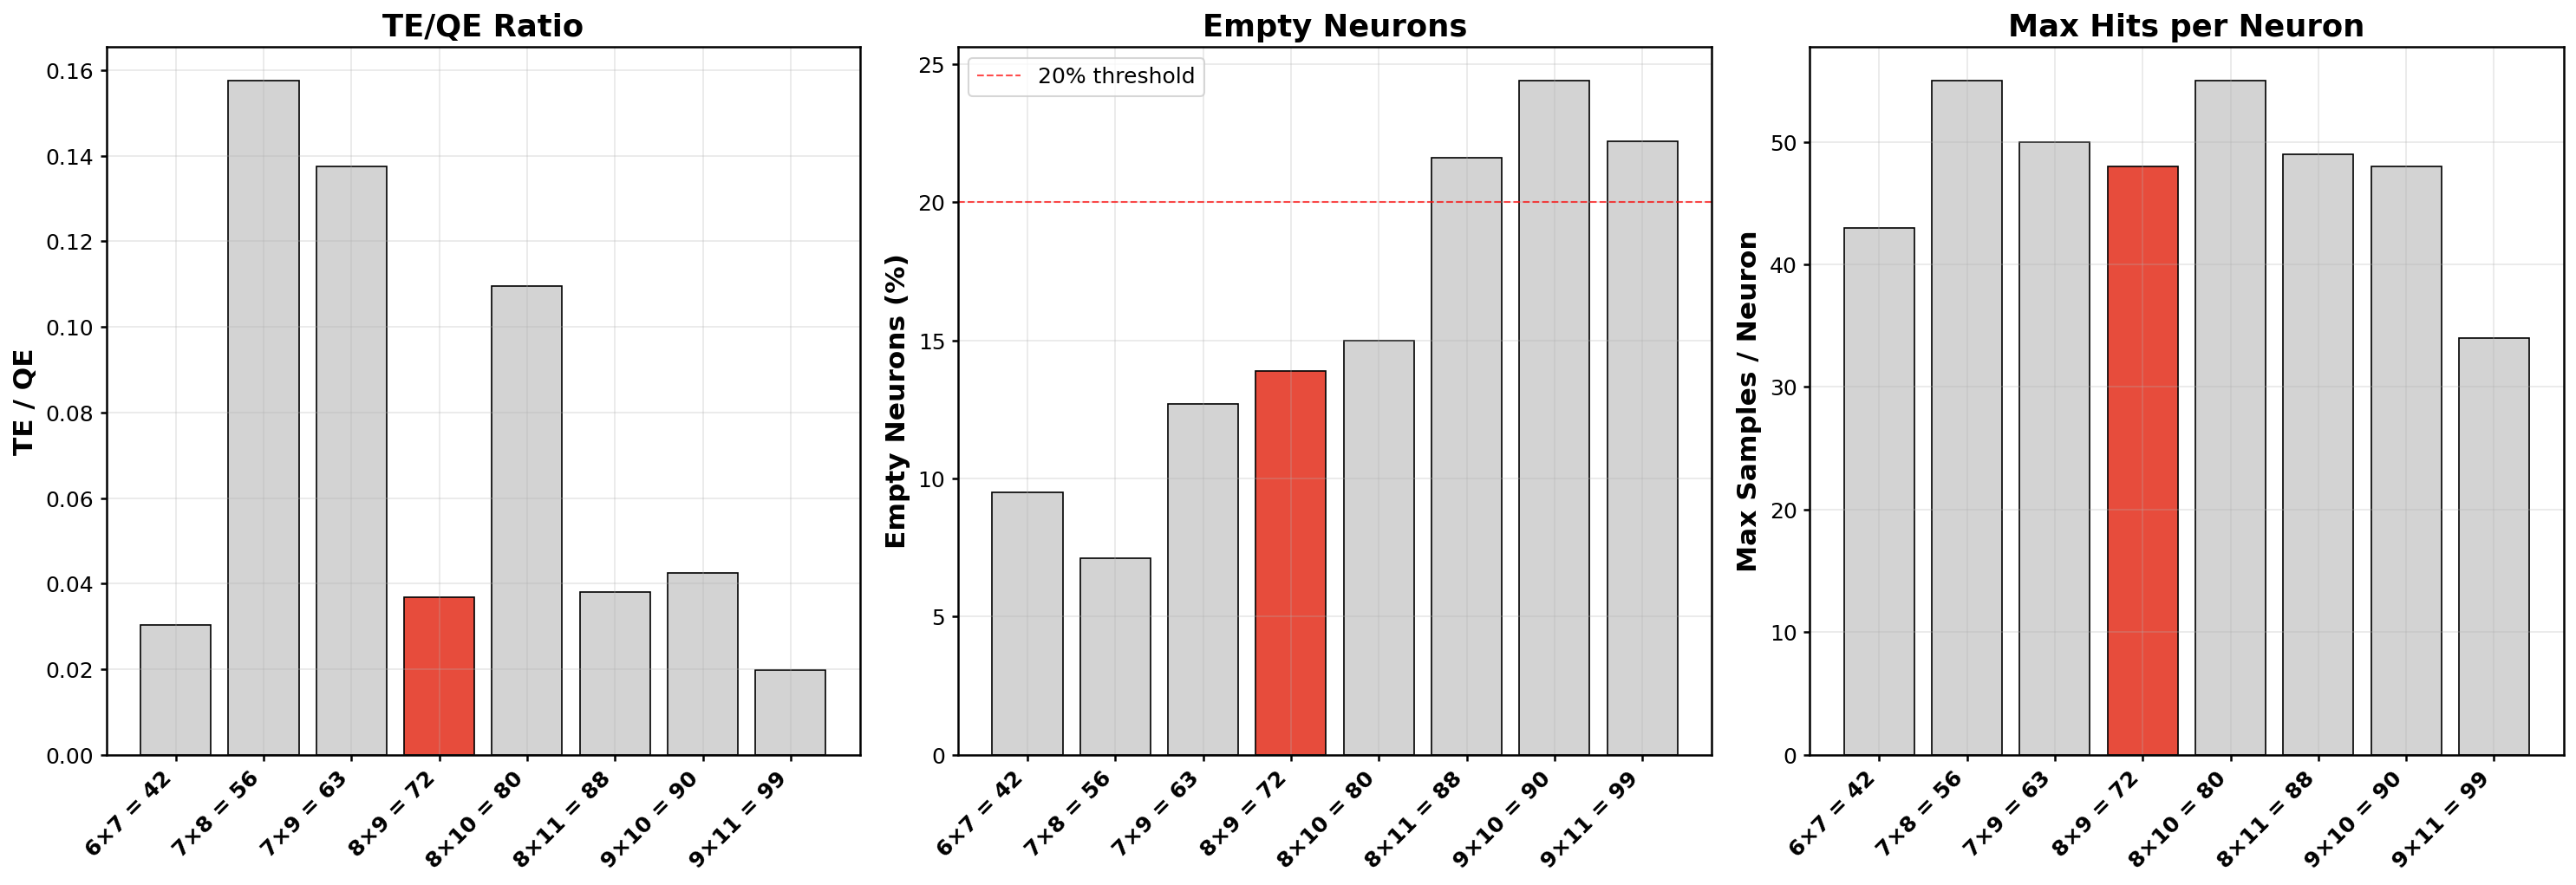

In [12]:
# ── 5.5  Grid selection summary - multi-criteria figure ──────────────

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

grid_labels = df_compare["Grid"].values
x = np.arange(len(grid_labels))

# Highlight the selected grid (8×9 = 72)
selected_idx = df_compare[df_compare["Neurons"] == 72].index[0]
colors = ["#E74C3C" if i == selected_idx else "lightgray" for i in range(len(grid_labels))]

# ── (a) TE/QE ratio ──────────────────────────────────────────────────
axes[0].bar(x, df_compare["TE/QE"], color=colors, edgecolor="black", linewidth=0.8)
axes[0].set_ylabel("TE / QE", fontsize=15, fontweight="bold")
axes[0].set_title("TE/QE Ratio", fontsize=17, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(grid_labels, rotation=45, ha="right", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="y", labelsize=12)

# ── (b) Empty neurons (%) ────────────────────────────────────────────
axes[1].bar(x, df_compare["Empty%"], color=colors, edgecolor="black", linewidth=0.8)
axes[1].set_ylabel("Empty Neurons (%)", fontsize=15, fontweight="bold")
axes[1].set_title("Empty Neurons", fontsize=17, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(grid_labels, rotation=45, ha="right", fontsize=12, fontweight="bold")
axes[1].tick_params(axis="y", labelsize=12)
axes[1].axhline(y=20, color="red", linestyle="--", linewidth=1, alpha=0.7, label="20% threshold")
axes[1].legend(fontsize=12)

# ── (c) Max samples per neuron ───────────────────────────────────────
axes[2].bar(x, df_compare["MaxHits"], color=colors, edgecolor="black", linewidth=0.8)
axes[2].set_ylabel("Max Samples / Neuron", fontsize=15, fontweight="bold")
axes[2].set_title("Max Hits per Neuron", fontsize=17, fontweight="bold")
axes[2].set_xticks(x)
axes[2].set_xticklabels(grid_labels, rotation=45, ha="right", fontsize=12, fontweight="bold")
axes[2].tick_params(axis="y", labelsize=12)

# Black axes for all panels
for ax in axes:
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)
    ax.tick_params(axis="both", colors="black", width=1.2)

# Print summary above figure
print(f"── Grid Selection Summary ─────────────────────────────────")
print(f"  PCA grid ratio √(λ1/λ2) = {ratio:.3f}")
print(f"  Vesanto target 5√N      = {M_target} neurons")
print(f"  Selected: 8×9 = 72 neurons (red bars)")
print(f"  TE/QE = {df_compare.loc[selected_idx, 'TE/QE']:.4f}, "
      f"Empty = {df_compare.loc[selected_idx, 'Empty%']:.1f}%, "
      f"MaxHits = {df_compare.loc[selected_idx, 'MaxHits']}")

plt.tight_layout()
fig.savefig(DIR_FIGURES / "SM06_SOM_grid_selection_multicriteria.png", dpi=600)
plt.show()

### <font color='orange'> **5) Final SOM (8 × 9 = 72 neurons, hexagonal)** </font>

> Sigma = 4.5 (half the longest grid side), learning rate 0.5, Gaussian neighborhood, PCA initialization, batch training, 10,000 iterations, seed 42.

#### 5.1 Training and convergence (diagnostic figure, not in the article)

── Final SOM Training Complete ─────────────────────────────
  Grid         : 8 × 9 = 72 neurons (hexagonal)
  Iterations   : 10000
  Final QE     : 1.0051
  Final TE     : 0.0369
  Final TE/QE  : 0.0368


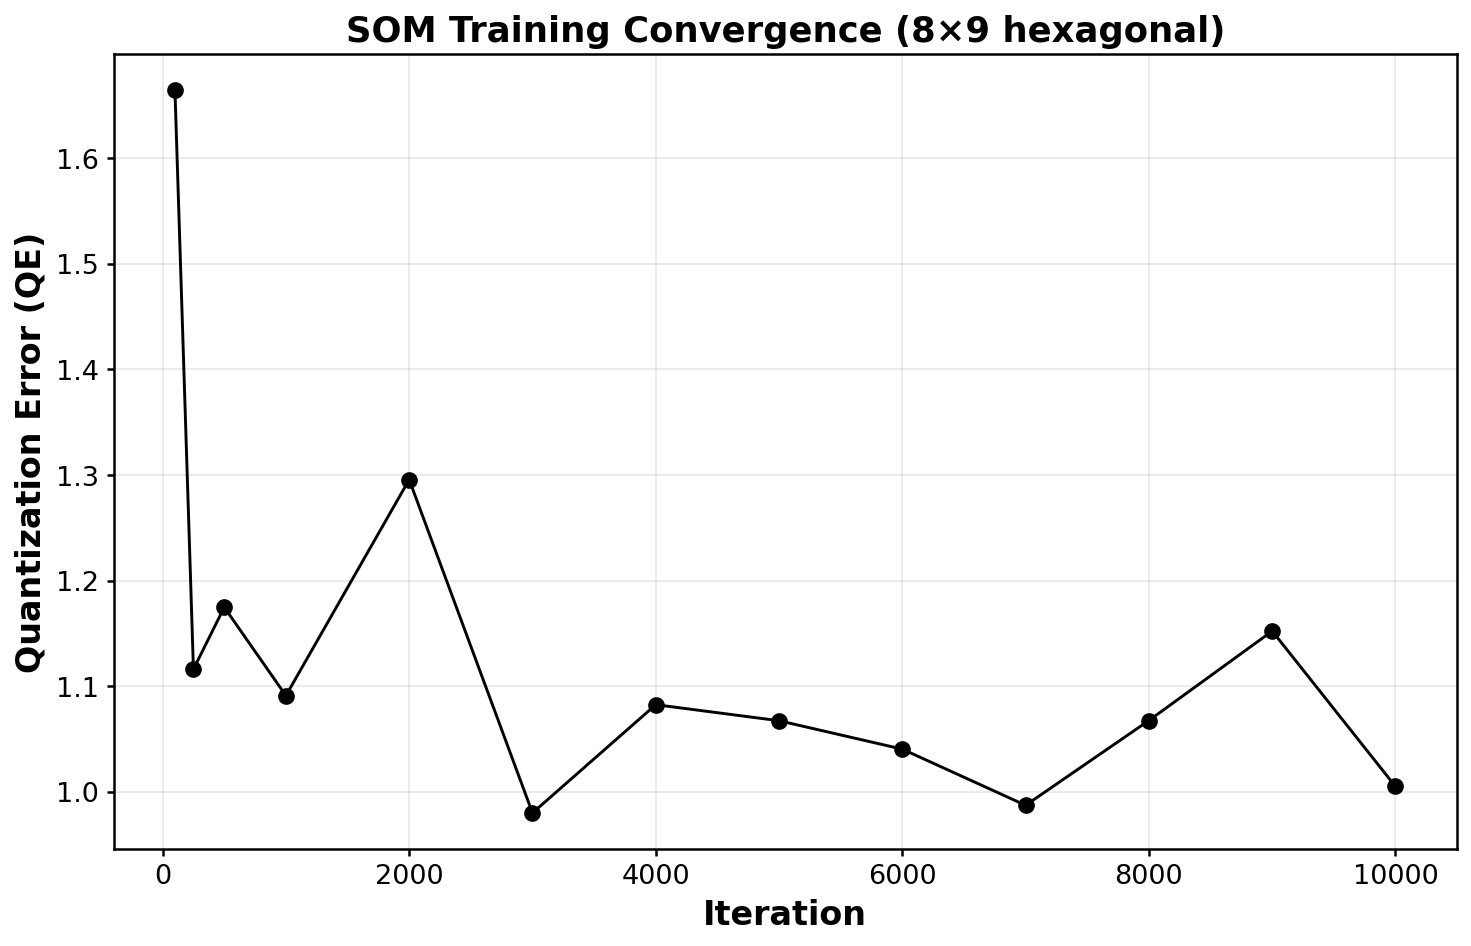

In [13]:
# ── 6.1  Final SOM training - 8×9 hexagonal ──────────────────────────

FINAL_ROWS = 8
FINAL_COLS = 9
N_ITER_FINAL = 10000

som_final = MiniSom(
    FINAL_ROWS, FINAL_COLS,
    data_som.shape[1],
    sigma=max(FINAL_ROWS, FINAL_COLS) / 2,
    learning_rate=0.5,
    neighborhood_function="gaussian",
    topology="hexagonal",
    random_seed=SEED,
)

# PCA-based initialization
som_final.pca_weights_init(data_som)

# ── Train all at once (avoids learning rate restart per chunk) ───────
som_final.train_batch(data_som, N_ITER_FINAL)

# Final metrics
final_qe = som_final.quantization_error(data_som)
final_te = som_final.topographic_error(data_som)

print(f"── Final SOM Training Complete ─────────────────────────────")
print(f"  Grid         : {FINAL_ROWS} × {FINAL_COLS} = {FINAL_ROWS * FINAL_COLS} neurons (hexagonal)")
print(f"  Iterations   : {N_ITER_FINAL}")
print(f"  Final QE     : {final_qe:.4f}")
print(f"  Final TE     : {final_te:.4f}")
print(f"  Final TE/QE  : {final_te / final_qe:.4f}")

# ── Convergence curve: retrain multiple times to show QE evolution ───
# Train from scratch at different iteration counts
checkpoints = [100, 250, 500, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
qe_history = []

for n_iter in checkpoints:
    som_tmp = MiniSom(
        FINAL_ROWS, FINAL_COLS, data_som.shape[1],
        sigma=max(FINAL_ROWS, FINAL_COLS) / 2,
        learning_rate=0.5,
        neighborhood_function="gaussian",
        topology="hexagonal",
        random_seed=SEED,
    )
    som_tmp.pca_weights_init(data_som)
    som_tmp.train_batch(data_som, n_iter)
    qe_history.append(som_tmp.quantization_error(data_som))

# ── Convergence plot ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(checkpoints, qe_history, "o-", color="black", linewidth=1.4, markersize=7)
ax.set_xlabel("Iteration", fontsize=16, fontweight="bold")
ax.set_ylabel("Quantization Error (QE)", fontsize=16, fontweight="bold")
ax.set_title(f"SOM Training Convergence ({FINAL_ROWS}×{FINAL_COLS} hexagonal)",
             fontsize=17, fontweight="bold")
ax.tick_params(axis="both", labelsize=13)

for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)
ax.tick_params(axis="both", colors="black", width=1.2)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "Diag_SOM_convergence_8x9.png", dpi=300)
plt.show()

#### 5.2 Component planes (diagnostic figure; the version with cluster boundaries is Figure SM7, in `02_HCA_clustering.ipynb`)

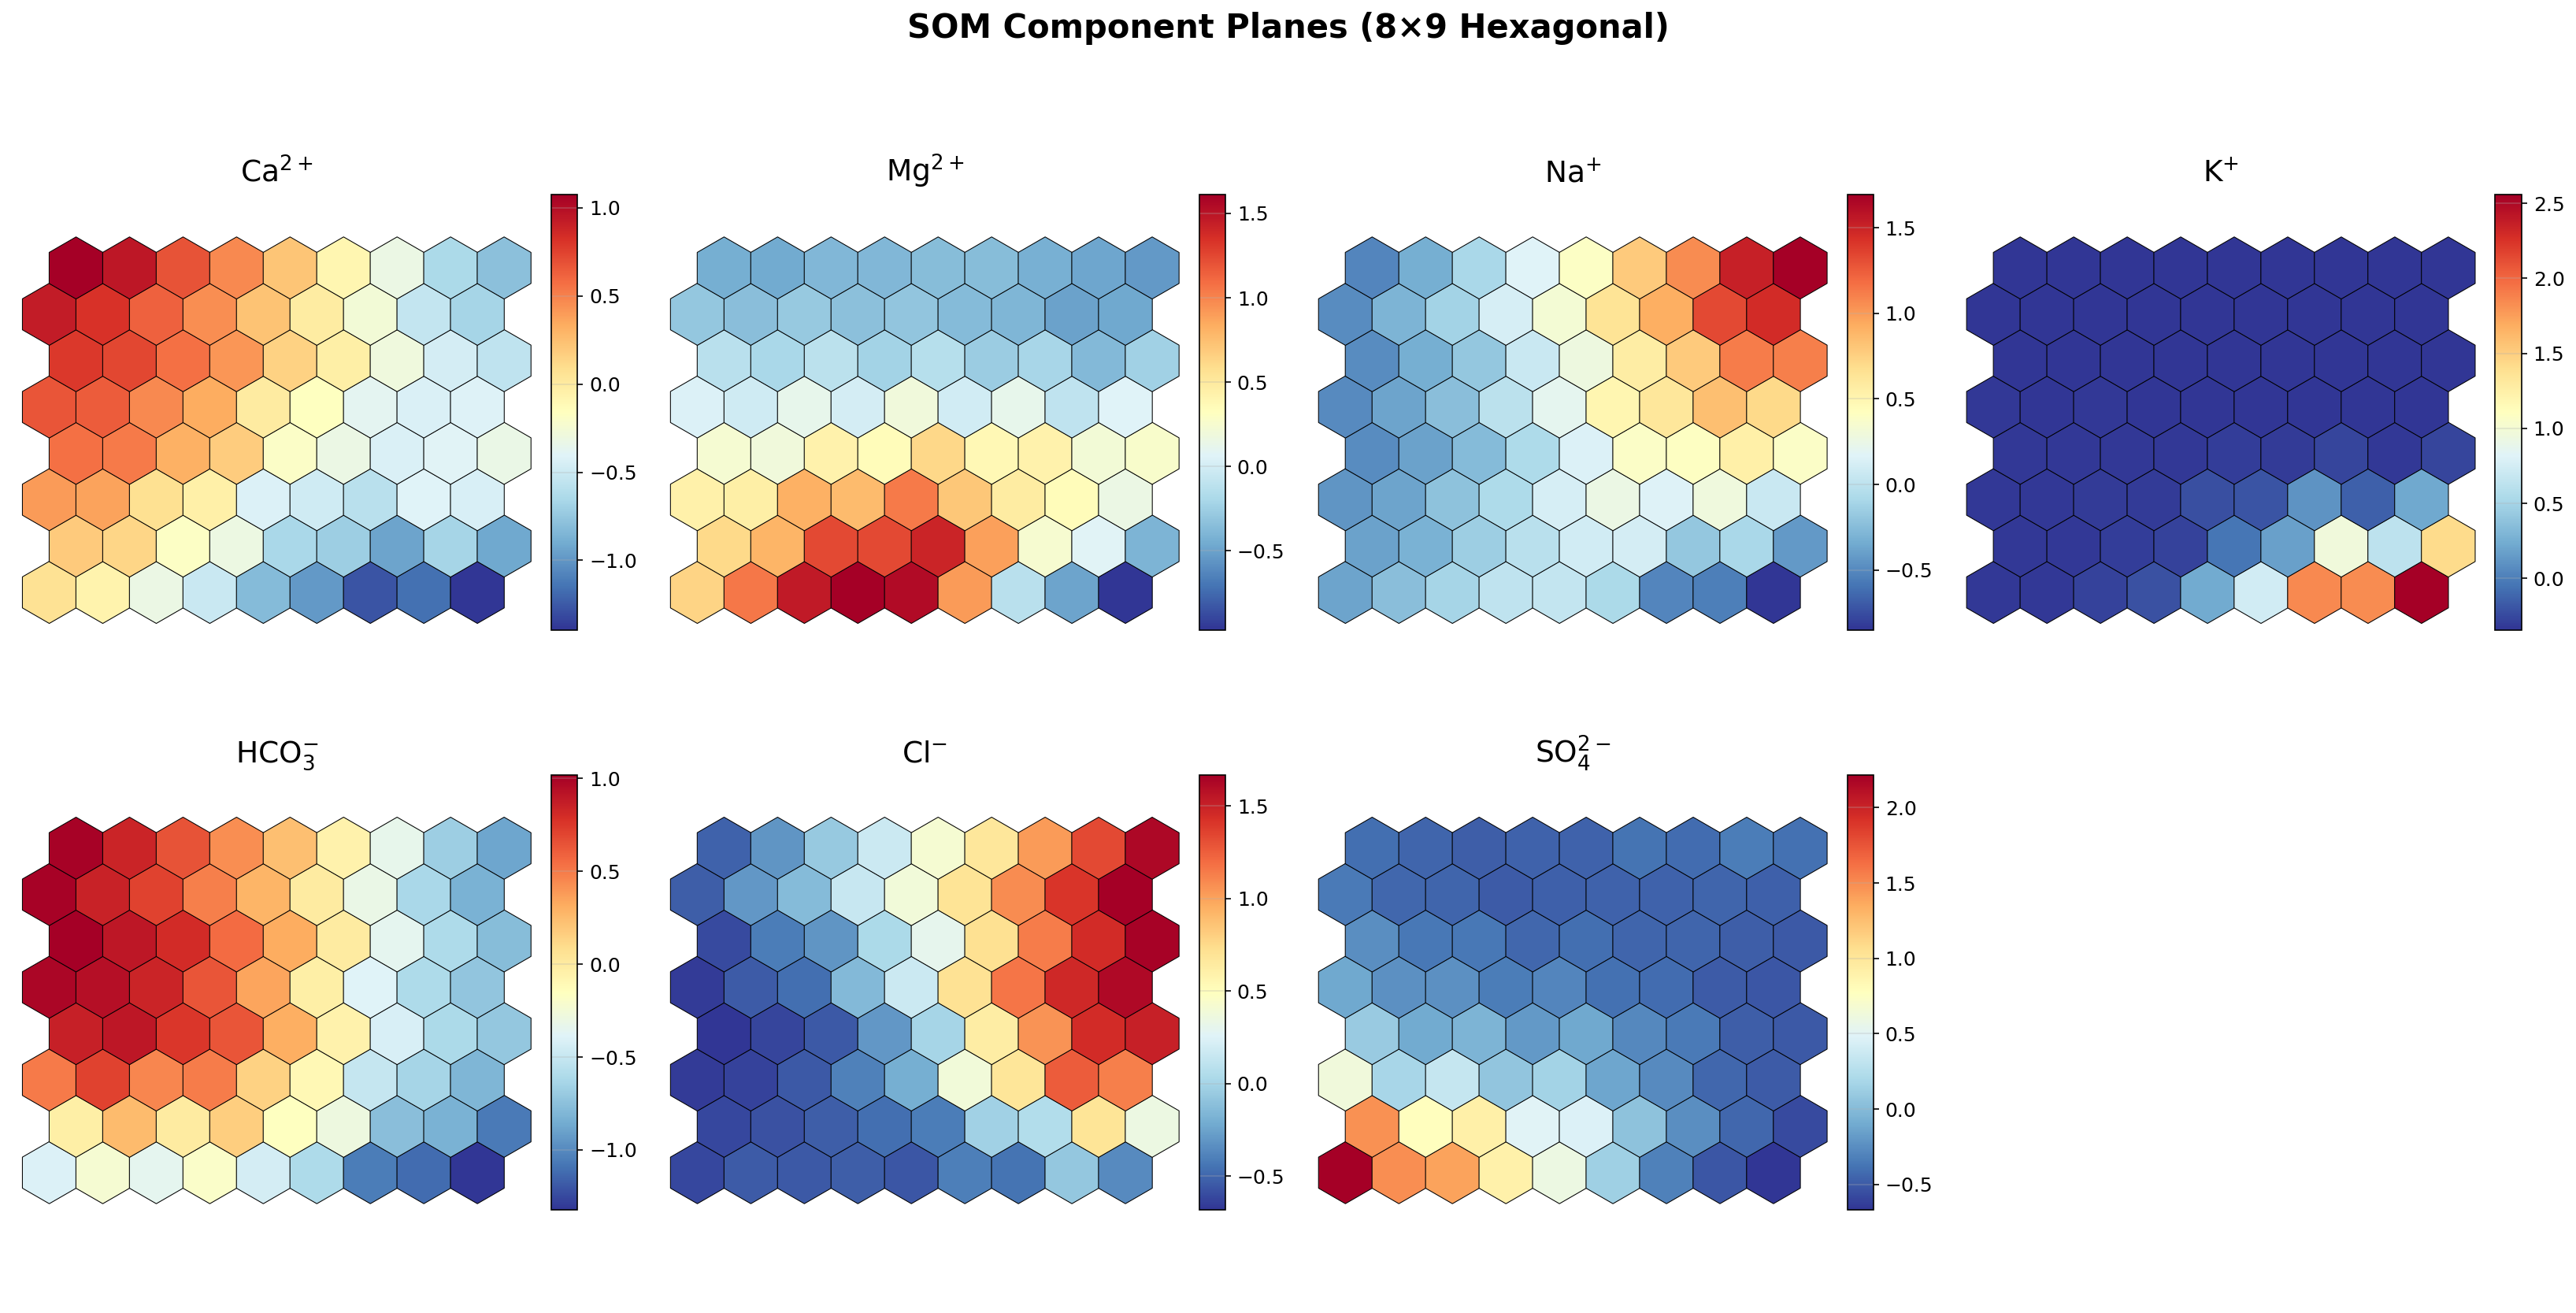

In [14]:
# ── 5.2  Component planes - 8×9 hexagonal ────────────────────────────

# LaTeX labels for ions
tex_labels = {
    "Ca":   r"$\mathrm{Ca^{2+}}$",
    "Mg":   r"$\mathrm{Mg^{2+}}$",
    "Na":   r"$\mathrm{Na^{+}}$",
    "K":    r"$\mathrm{K^{+}}$",
    "HCO3": r"$\mathrm{HCO_{3}^{-}}$",
    "Cl":   r"$\mathrm{Cl^{-}}$",
    "SO4":  r"$\mathrm{SO_{4}^{2-}}$",
}

def plot_hex_component_plane(weights, feature_idx, ion_label, ax, cmap="RdYlBu_r"):
    """Plot one component plane on a hexagonal grid."""
    rows, cols, _ = weights.shape
    values = weights[:, :, feature_idx]

    vmin, vmax = values.min(), values.max()
    norm = plt.Normalize(vmin=vmin, vmax=vmax)

    patches = []
    colors = []

    for r in range(rows):
        for c in range(cols):
            # Hex offset: odd rows shifted right by 0.5
            x = c + 0.5 * (r % 2)
            y = r * np.sqrt(3) / 2

            hex_patch = RegularPolygon(
                (x, y), numVertices=6, radius=0.58,
                orientation=0, linewidth=0.5, edgecolor="black"
            )
            patches.append(hex_patch)
            colors.append(values[r, c])

    pc = PatchCollection(patches, cmap=cmap, edgecolors="black", linewidths=0.5)
    pc.set_array(np.array(colors))
    pc.set_clim(vmin, vmax)
    ax.add_collection(pc)

    # Axis limits
    ax.set_xlim(-0.7, cols + 0.2)
    ax.set_ylim(-0.7, rows * np.sqrt(3) / 2 + 0.5)
    ax.set_aspect("equal")
    ax.set_title(tex_labels[ion_label], fontsize=18, fontweight="bold", pad=8)
    ax.axis("off")

    # Colorbar
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.08)
    cbar = plt.colorbar(pc, cax=cax)
    cbar.ax.tick_params(labelsize=12)


weights = som_final.get_weights()  # shape: (8, 9, 7)

# Composite figure (2×4)
fig, axes = plt.subplots(2, 4, figsize=(22, 11))

for idx, ion in enumerate(ION_LABELS):
    row = idx // 4
    col = idx % 4
    plot_hex_component_plane(weights, idx, ion, axes[row, col])

axes[1, 3].axis("off")

plt.suptitle(f"SOM Component Planes ({FINAL_ROWS}×{FINAL_COLS} Hexagonal)",
             fontsize=20, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(DIR_FIGURES / "Diag_SOM_component_planes_8x9.png", dpi=300)
plt.show()

#### 5.3 U-matrix and hit map (diagnostic figure, not in the article)

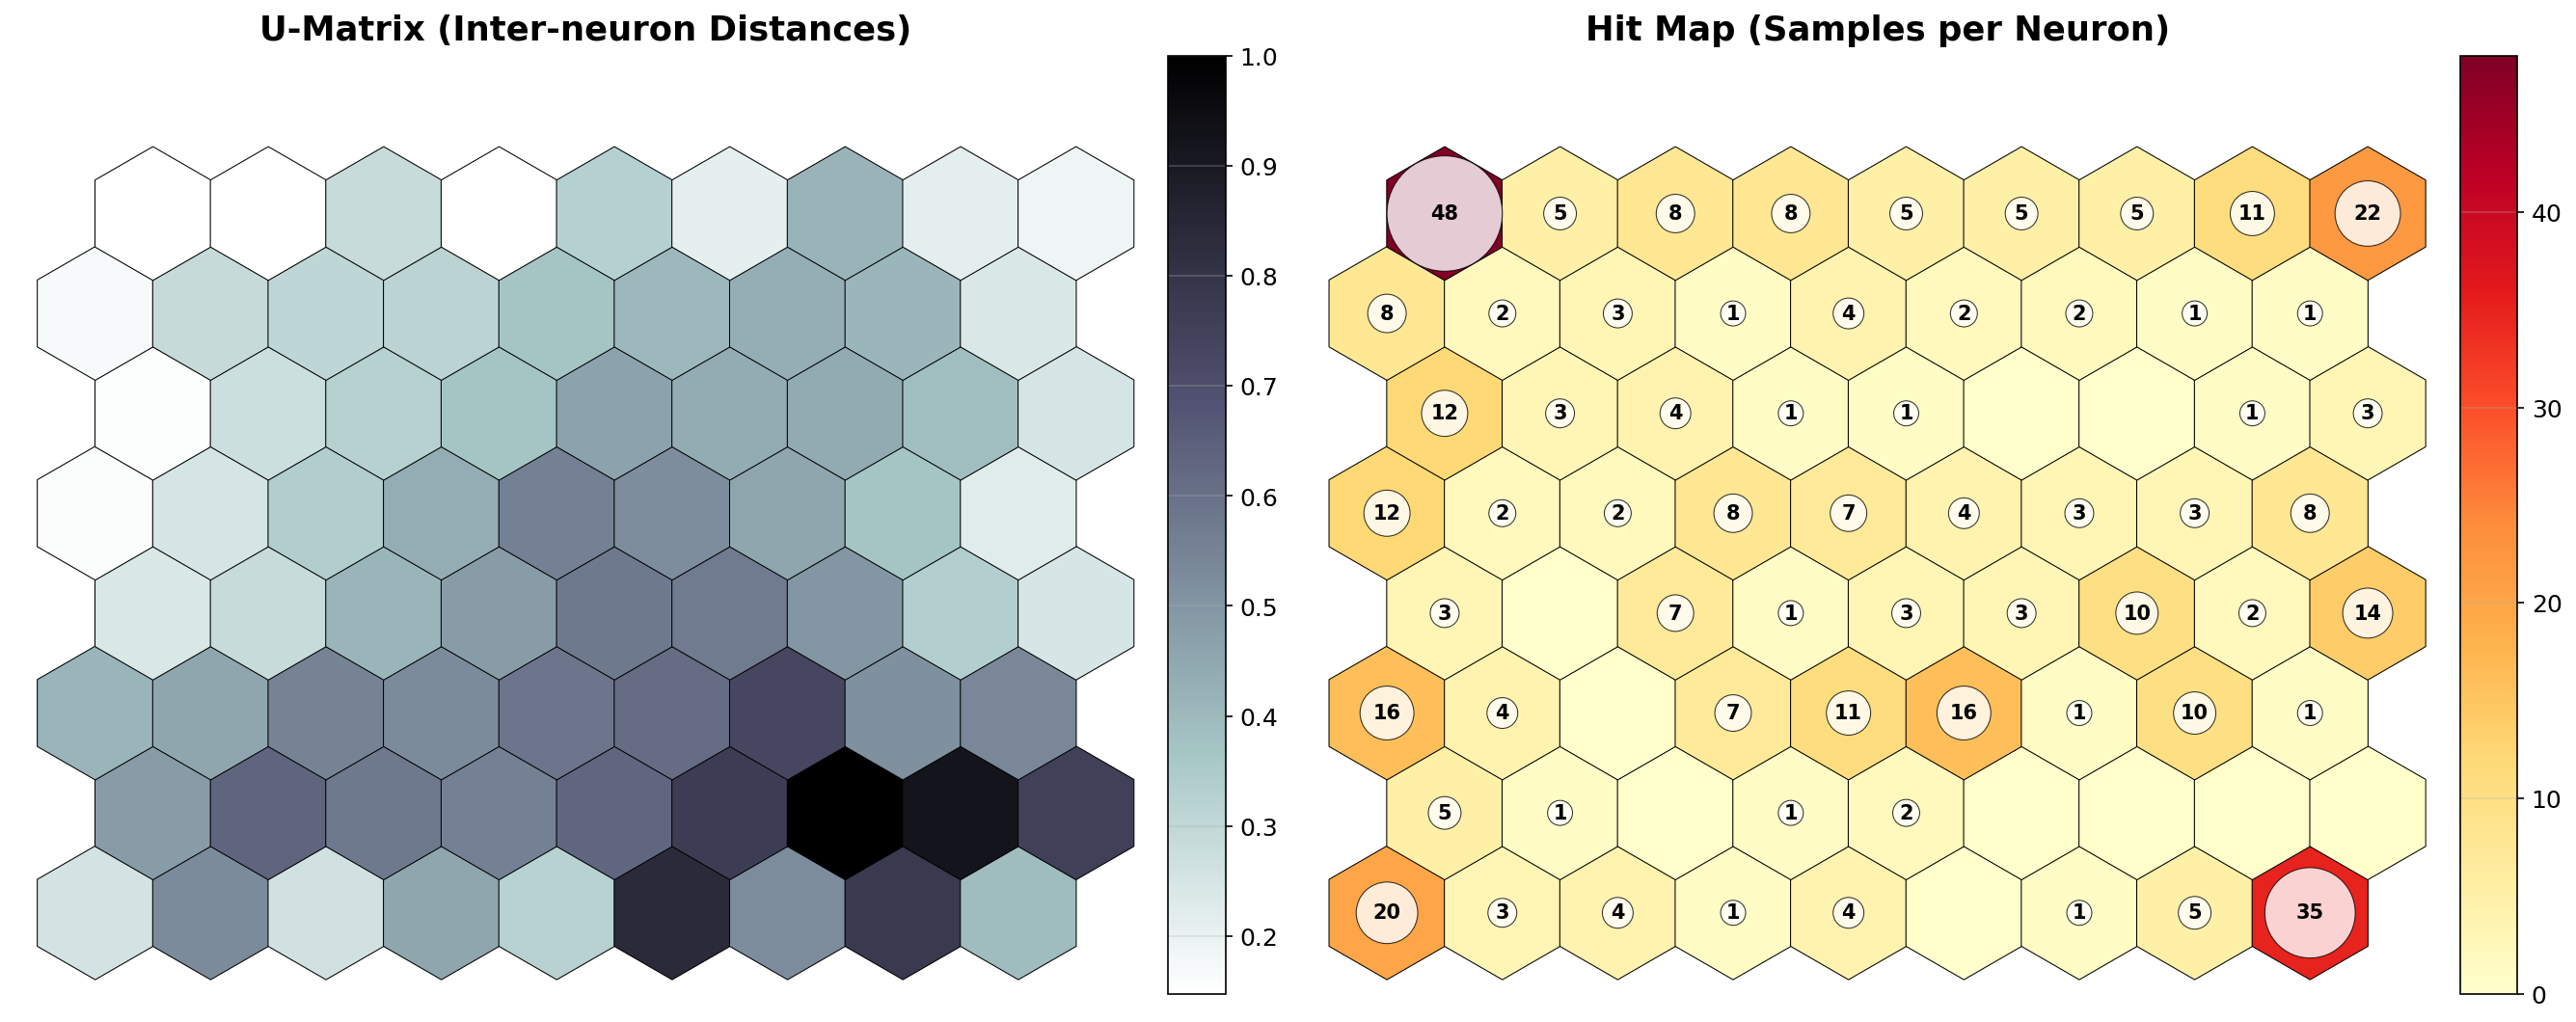

── SOM Map Statistics (8×9) ───────────────────────────────
  Total neurons      : 72
  Empty neurons      : 10 (13.9%)
  Occupied neurons   : 62
  Avg samples/neuron : 6.5
  Max samples/neuron : 48
  Min (non-zero)     : 1


In [15]:
# ── 5.3  U-matrix & Hit map - 8×9 hexagonal ──────────────────────────

# ── Plot function for hex grid with values ───────────────────────────
def plot_hex_map(values, ax, cmap, title, show_hits=False, hits=None):
    """Plot a hexagonal map with optional hit circles."""
    rows, cols = values.shape
    patches = []
    colors = []

    for r in range(rows):
        for c in range(cols):
            x = c + 0.5 * (r % 2)
            y = r * np.sqrt(3) / 2
            hex_patch = RegularPolygon(
                (x, y), numVertices=6, radius=0.58,
                orientation=0, linewidth=0.5, edgecolor="black"
            )
            patches.append(hex_patch)
            colors.append(values[r, c])

    pc = PatchCollection(patches, cmap=cmap, edgecolors="black", linewidths=0.5)
    pc.set_array(np.array(colors))
    pc.set_clim(values.min(), values.max())
    ax.add_collection(pc)

    # Overlay hit circles if requested
    if show_hits and hits is not None:
        max_hits = hits.max()
        for r in range(rows):
            for c in range(cols):
                if hits[r, c] > 0:
                    x = c + 0.5 * (r % 2)
                    y = r * np.sqrt(3) / 2
                    # Circle size proportional to hit count
                    size = 0.1 + 0.4 * (hits[r, c] / max_hits)
                    circle = plt.Circle((x, y), size, color="white",
                                        ec="black", linewidth=0.5, alpha=0.8)
                    ax.add_patch(circle)
                    ax.text(x, y, str(hits[r, c]), ha="center", va="center",
                            fontsize=10, fontweight="bold")

    ax.set_xlim(-0.7, cols + 0.2)
    ax.set_ylim(-0.7, rows * np.sqrt(3) / 2 + 0.5)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=17, fontweight="bold", pad=8)
    ax.axis("off")

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.08)
    cbar = plt.colorbar(pc, cax=cax)
    cbar.ax.tick_params(labelsize=12)


# U-matrix
u_matrix = som_final.distance_map()

# Hit map
hit_map = np.zeros((FINAL_ROWS, FINAL_COLS), dtype=int)
for sample in data_som:
    bmu = som_final.winner(sample)
    hit_map[bmu] += 1

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

plot_hex_map(u_matrix, ax1, cmap="bone_r",
             title="U-Matrix (Inter-neuron Distances)")

plot_hex_map(hit_map.astype(float), ax2, cmap="YlOrRd",
             title="Hit Map (Samples per Neuron)",
             show_hits=True, hits=hit_map)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "Diag_SOM_umatrix_hitmap_8x9.png", dpi=300)
plt.show()

# Statistics
n_empty = (hit_map == 0).sum()
n_occupied = FINAL_ROWS * FINAL_COLS - n_empty
print(f"── SOM Map Statistics (8×9) ───────────────────────────────")
print(f"  Total neurons      : {FINAL_ROWS * FINAL_COLS}")
print(f"  Empty neurons      : {n_empty} ({100*n_empty/(FINAL_ROWS*FINAL_COLS):.1f}%)")
print(f"  Occupied neurons   : {n_occupied}")
print(f"  Avg samples/neuron : {data_som.shape[0] / n_occupied:.1f}")
print(f"  Max samples/neuron : {hit_map.max()}")
print(f"  Min (non-zero)     : {hit_map[hit_map > 0].min()}")

#### 5.4 Save the trained SOM, codebook vectors and BMU assignments

In [16]:
# ── 5.4  Save trained SOM model & outputs ────────────────────────────

# ── Save SOM model (pickle), reloaded by 02_HCA_clustering.ipynb ─────
som_model_path = DIR_INTERMED / "som_model_final.p"
with open(som_model_path, "wb") as f:
    pickle.dump(som_final, f)
print(f"Saved SOM model: {som_model_path.relative_to(ROOT)}")

# ── Save codebook vectors as numpy array ────────────────────────────
codebook_path = DIR_INTERMED / "som_codebook_vectors.npy"
np.save(codebook_path, weights)
print(f"Saved codebook : {codebook_path.relative_to(ROOT)}  shape={weights.shape}")

# ── Save BMU assignments for each sample ────────────────────────────
bmu_list = []
for i, sample in enumerate(data_som):
    bmu = som_final.winner(sample)
    bmu_list.append({"SampleID": df["SampleID"].iloc[i],
                     "BMU_row": bmu[0], "BMU_col": bmu[1]})

df_bmu = pd.DataFrame(bmu_list)
bmu_path = DIR_INTERMED / "som_bmu_assignments.xlsx"
df_bmu.to_excel(bmu_path, index=False)
print(f"Saved BMU table: {bmu_path.relative_to(ROOT)}  ({len(df_bmu)} samples)")

# ── Summary ─────────────────────────────────────────────────────────
print(f"\n── Summary ────────────────────────────────────────────────")
print(f"  Grid        : {FINAL_ROWS}×{FINAL_COLS} = {FINAL_ROWS*FINAL_COLS} neurons (hexagonal)")
print(f"  QE          : {final_qe:.4f}")
print(f"  TE          : {final_te:.4f}")
print(f"  Empty       : {n_empty} ({100*n_empty/(FINAL_ROWS*FINAL_COLS):.1f}%)")
print(f"  Max hits    : {hit_map.max()}")
print(f"\n  → Next: 02_HCA_clustering.ipynb")

# ── Check against the article ────────────────────────────────────────
assert np.allclose(var_pct[:4].round(1), [36.7, 26.0, 18.4, 11.2])        # Figure 5, Figure SM3
assert np.allclose(corr_loadings[:, 0].round(4), [-0.8663, 0.0278, 0.6360, 0.2822, -0.8814, 0.7509, -0.0340])  # PC1 as in Figure 5b
assert (FINAL_ROWS, FINAL_COLS) == (8, 9) and n_empty == 10 and hit_map.max() == 48
print("\n✓ Matches the article: PC1-PC4 = 36.7/26.0/18.4/11.2 %, 8 × 9 SOM, 10 empty neurons (13.9 %), max 48 samples per neuron.")

Saved SOM model: outputs\intermediate\som_model_final.p
Saved codebook : outputs\intermediate\som_codebook_vectors.npy  shape=(8, 9, 7)
Saved BMU table: outputs\intermediate\som_bmu_assignments.xlsx  (406 samples)

── Summary ────────────────────────────────────────────────
  Grid        : 8×9 = 72 neurons (hexagonal)
  QE          : 1.0051
  TE          : 0.0369
  Empty       : 10 (13.9%)
  Max hits    : 48

  → Next: 02_HCA_clustering.ipynb

✓ Matches the article: PC1-PC4 = 36.7/26.0/18.4/11.2 %, 8 × 9 SOM, 10 empty neurons (13.9 %), max 48 samples per neuron.


---
**Figures:** Figure 5, SM3, SM4, SM5, SM6 in `outputs/figures/` (+ `Diag_*` SOM diagnostics)

**Outputs:** `outputs/intermediate/som_model_final.p`, `som_codebook_vectors.npy`, `som_bmu_assignments.xlsx`; `outputs/tables/som_grid_optimization_metrics.xlsx`

**Next:** `02_HCA_clustering.ipynb` (number of clusters, HCA on the SOM codebook; SM7-SM9)